[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QAL_AdversarialSampling_Casares2020.ipynb)

# Quantum active learning for adversarial robustness: Casares and Martin-Delgado (2020) step by step

**Paper.** P. A. M. Casares and M. A. Martin-Delgado, *A quantum active learning algorithm for sampling against
adversarial attacks*, New Journal of Physics **22**, 073026 (2020). arXiv:1912.03283 (v3, 19 Jul 2020).
DOI 10.1088/1367-2630/ab9ac9 (see `manifest.csv`, row QC-338).

**What this notebook does.** The paper is an *algorithm and complexity* paper: it contains no experiment, no data set and no
accuracy table. A reproduction therefore means: implement every piece of the algorithm that a laptop can run, check each
mathematical or complexity claim numerically, and measure whether the idea (sample the most "informative" points so that the
minimum distance between classes can be learned, then use the Khoury and Hadfield-Menell theorem) helps a real classifier
under real attacks. Concretely the notebook

1. loads **real MNIST digits** (a 3-versus-5 pair, public data from Hugging Face / OpenML) and explores them (section 1);
2. implements the paper's **least-squares SVM, class probability and "informativeness"** exactly (sections 2 and 3);
3. builds the **actual quantum circuits** of the algorithm on a Qiskit statevector simulator: the swap test with amplitude-loaded
   states (paper eqs. 10-13), the Grover operator and **amplitude estimation**, and **amplitude amplification** (section 4);
   every vectorised formula used later is asserted equal to these circuits;
4. checks the paper's **numerical claims** one by one (section 5): the swap-test probability and the sign rule, the
   amplitude-estimation precision O(1/eps) against classical O(1/eps^2), the sampling rule of Algorithm 1 (probability 1 - e^-beta
   of a point in the top 1/C quantile with c = O(beta C) draws), the O(sqrt(C)) cost of amplitude amplification, the
   threshold-strategy table of Appendix C, the low-rank (kappa_eff) error O(n^-1/2) and the classical cost scaling;
5. runs a **pool-based active-learning experiment** on the MNIST pair: the paper's sampler versus random and uncertainty
   sampling, scored by how well the minimum class distance r_p is learned and by clean and **adversarial accuracy under L2 PGD
   attacks** on a linear and an RBF classifier and on 1-nearest-neighbour (the classifier assumed by the theorem), section 6;
6. prints a **claim-by-claim verdict table** (section 7), a critical reading and exercises.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` finishes in a few minutes (pool 1200, 3 seeds, 80 labels); `FAST_MODE = False` is the full budget
(pool 3000, 5 seeds, 200 labels, about 40 minutes on a busy laptop CPU). The outputs stored in this copy come from the `FAST_MODE = False` run. No GPU, no IBM account and no token
are needed (MNIST is public). **You get at the end:** drawn circuits with qubit / depth / parameter counts, scaling plots with fitted
exponents, the active-learning curves, and an honest verdict for each claim.

**Honest scope.** The exponential speed-up of the paper (polylogarithmic in the data size n and dimension m) needs a qRAM and
fault-tolerant hardware. It cannot be tested here. What *can* be tested is stated above; what cannot is marked
"cannot be checked" with the reason.

## The paper in one page

**Problem.** Adversarial examples are small perturbations that flip a classifier's decision. Khoury and Hadfield-Menell (KH,
arXiv:1811.00525, theorem 5; theorem 1 in this paper) prove: if the classes are separated by a distance r_p, the learner is
locally stable, and the labelled training set X_L is a **delta-cover** of the classes with **delta < r_p - eps**, then the
classifier is correct on the whole eps-neighbourhood of the classes, i.e. robust against every perturbation of norm <= eps.
The catch: r_p (the smallest distance between the classes) is unknown, and a wrong estimate either breaks the theorem
(r_p too large) or makes the cover needlessly expensive (r_p too small).

**Idea.** Use *active learning* to find r_p: ask for labels of the points that most improve the estimate of r_p.
A class-membership rule (point i is in class j if c_ij > 0.8) keeps the classes disjoint. The two-class SVM
w.x - b = 0 has margin 1/|w| = r_p/2 if it were perfect, so a better estimate means a larger |w|.

**Informativeness (eq. 2).** I(x) = P_c(x) * |w_{n+1}|: the probability that x belongs to class c times the norm of the weight
vector of the SVM after x is added to the training set with label c ("expected information gain").

**Quantum algorithm (Algorithm 1).** Repeat O(C beta) times: sample a point x uniformly, evaluate P_c(x) with the quantum SVM of
Rebentrost-Mohseni-Lloyd (least-squares SVM, eq. 9, solved with HHL-type linear algebra and qRAM), read P_c with a swap test and
**amplitude estimation** (eq. 12-13), compute |w_{n+1}| with a Chebyshev / linear-combination-of-unitaries matrix-vector product
and one more amplitude estimation (eq. 25-32, appendix D), and keep the best point. The best of O(C beta) uniform draws lies in
the top 1/C quantile of informativeness with probability 1 - e^-beta (eqs. 33-35).

**Complexity claims.** Overall O~(C beta eps^-1 (o |F|^2 kappa_eff^3 eps^-3 + polylog(kappa_M eps^-1 (n+m)))) with error
O~(eps + n^-1/2): polylogarithmic in n and m (qRAM), polynomial in 1/eps; Appendix C: classical greedy O(beta C) (deterministic
score) and Omega(beta^2 C) (noisy score), classical threshold O(eps^-2 beta C), quantum threshold O(eps^-1 beta C); amplitude
amplification costs O(sqrt(C)). Appendix E: the algorithm can be dequantised, leaving a polynomial speed-up.

**Data / metrics in the paper.** None. There is no table or figure with numbers (Fig. 1 and 2 are sketches).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | none (images are a motivating example) | **MNIST digits 3 vs 5** (real, public). CHOICE: the paper's example is an image classifier; MNIST is the standard small image benchmark used in the sibling robustness notebooks of this folder |
| Classifier | least-squares SVM (eq. 9), linear kernel K = x.x | same; regulariser `REG` = 1/gamma = 1.0 (CHOICE, paper: "specified by the user") |
| P_c(x) | swap-test probability, "or apply whatever activation function ... like a sigmoid" | P_c = sigmoid(ln 4 * f(x)) with f = w.x + b, so that the margin hyperplanes f = +-1 give exactly the paper's membership threshold 0.8 (CHOICE) |
| Informativeness | P_c(x) |w_{n+1}| where "the point is in class c" | expected value over both classes P_+ |w^+| + P_- |w^-| (main rule, matches "expected value of information", Def. 1); the single predicted-class product P_c |w| is run as an ablation (CHOICE) |
| Candidate points | uniform samples of the whole space (query synthesis), or a pool | **pool-based**: candidates are drawn uniformly from an unlabelled pool of real digits (uniform draws in a 784-dimensional pixel cube are noise images; the paper says the algorithm can be used pool-based) |
| Quantum solver of eq. 9 | HHL + qRAM + Hamiltonian simulation | **not simulated**: |b, alpha> is obtained by exact linear algebra; only its *use* (swap test, amplitude estimation, amplification) is run as circuits. A generic amplitude loader (no qRAM) is used on a small real instance |
| Amplitude estimation | canonical (QPE based), cost O(1/eps) | canonical QAE circuit (Hadamards, controlled Q^(2^j), inverse QFT), exact output distribution |
| Sampling rule | c = O(beta C) draws, best of them | c = ceil(beta / -ln(1 - 1/C)) (the exact bound of eq. 34); beta = 3, C = 20 |
| Baselines | none | random sampling, uncertainty sampling (closest to the hyperplane), exhaustive informativeness (classical, whole pool) |
| Attacks | none (theorem only) | L2 PGD against linear and RBF-SVM models (unclipped for the linear model, so the attack is exact; clipped to [0,1] for the RBF model), exact certified radius and bisector attack for 1-NN |
| Tolerances | n/a | 2 accuracy points / 0.02 for probabilities; scaling claims judged by fitted exponents (+-0.15) |

In [1]:
# Install (pinned to the versions this notebook was tested with). Colab already ships numpy, pandas, scipy,
# scikit-learn and matplotlib; on a machine that already has Qiskit 2.5.2 nothing is reinstalled.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
def _needs_install():
    try:
        import qiskit, pylatexenc, pyarrow, PIL, huggingface_hub   # noqa: F401
        return qiskit.__version__ != "2.5.2"
    except Exception:
        return True
if IN_COLAB or _needs_install():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "pylatexenc",
                           "pyarrow", "pillow", "huggingface_hub"])
    print("Installed. If Colab asks for a runtime restart, restart and run all cells again.")
else:
    print("Required packages already present.")

Required packages already present.


In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant)
SEED = 42                      # master seed
FAST_MODE = False              # True: a few minutes (small pool, 3 seeds). False: full budget (bigger pool, 5 seeds), see the cell below
IBM_TOKEN = ""                 # not used: everything runs on the exact statevector simulator
DATA_DIR = "qc338_data"        # MNIST cache (about 20 MB)

DIGITS = (3, 5)                # CHOICE: the digit pair (label -1 = first digit, +1 = second digit)
REG = 1.0                      # CHOICE: LS-SVM regulariser 1/gamma of eq. (9)
A_SCALE = float(__import__("math").log(4.0))   # CHOICE: P_c = sigmoid(A_SCALE * f); f = +-1 (the margin) -> 0.8, the paper's class threshold
C_QUANT, BETA = 20, 3.0        # Algorithm 1: top-1/C quantile with probability 1 - exp(-BETA)  (c = ceil(BETA / -ln(1 - 1/C)) draws)
N0 = 10                        # initial labelled points (5 per class)
EPS_GRID = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0]   # L2 attack radii (pixel units, images have |x|_2 of about 9)
EPS_REF = 1.0                  # attack radius used for the single-number comparison
EPS_HEAVY = [0.5, 1.0, 1.5, 2.0, 3.0]                    # radii for the RBF-SVM and 1-NN attacks (contains EPS_REF)
PGD_STEPS = 20                 # PGD steps for the linear model (checked against the exact analytic result)

if FAST_MODE:
    PGD_STEPS_RBF, N_ATK = 10, 150                            # PGD steps and attacked test images for the RBF-SVM / 1-NN attacks
    POOL_N, TEST_N, BUDGET, N_SEEDS = 1200, 500, 80, 3        # unlabelled pool, test images, total labels, seeds
    QAE_MS = list(range(1, 11))                               # evaluation qubits used in the QAE scaling study (analytic)
    MC_TRIALS = 4000                                          # Monte-Carlo trials for the sampling-rule checks
    LOWRANK_NS = [25, 50, 100, 200, 400, 800]                 # sizes for the kappa_eff study
    TIME_NS, TIME_MS = [100, 200, 400, 800], [49, 196, 784]   # sizes for the classical timing study
    SP_QUBITS = [2, 3, 4, 5, 6, 7]                            # qubits of the generic state-preparation resource study
else:
    PGD_STEPS_RBF, N_ATK = 20, 400
    POOL_N, TEST_N, BUDGET, N_SEEDS = 3000, 1000, 200, 5
    QAE_MS = list(range(1, 13))
    MC_TRIALS = 20000
    LOWRANK_NS = [25, 50, 100, 200, 400, 800, 1600, 3000]
    TIME_NS, TIME_MS = [100, 200, 400, 800, 1600], [49, 196, 784]
    SP_QUBITS = [2, 3, 4, 5, 6, 7, 8]
print(f"FAST_MODE={FAST_MODE}  pool={POOL_N}  test={TEST_N}  budget={BUDGET}  seeds={N_SEEDS}  digits={DIGITS}")

FAST_MODE=False  pool=3000  test=1000  budget=200  seeds=5  digits=(3, 5)


In [3]:
import os, io, math, time, warnings, importlib.metadata as _md
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import special, stats
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation, QFTGate, UnitaryGate, DiagonalGate, grover_operator
from qiskit.quantum_info import Statevector, Operator

rng_global = np.random.default_rng(SEED)
DATA = Path(DATA_DIR); DATA.mkdir(exist_ok=True)

# Hugging Face token (MNIST is public, so None works; a gated mirror would need the reader's own token in Colab Secrets).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("qiskit", qiskit.__version__, "| numpy", np.__version__, "| scipy", __import__("scipy").__version__,
      "| sklearn", __import__("sklearn").__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | pandas 3.0.6


## 1. Dataset Exploration and Visualisation

The paper names no data set. Its running example is an image classifier, so this notebook uses **real MNIST digits**
(CHOICE). Every statistic below is computed on the real images; nothing is simulated or relabelled. The two classes used by the
experiments are the digits **3 (label -1)** and **5 (label +1)**; the other eight digits are shown only to give the context of the
labelled projection. Pixels are scaled to [0, 1]; the images are flattened to m = 784 features (one per pixel).

In [4]:
def load_mnist():
    """MNIST from the Hugging Face mirror ylecun/mnist (public); OpenML as fallback. Returns uint8 images and labels."""
    from PIL import Image
    try:
        from huggingface_hub import hf_hub_download
        out = {}
        for split in ["train", "test"]:
            p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                                local_dir=str(DATA / "hf_mnist"), token=HF_TOKEN)
            df = pd.read_parquet(p)
            imgs = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).reshape(len(df), -1)
            out[split] = (imgs.astype(np.uint8), df["label"].to_numpy().astype(int))
        return out["train"], out["test"], "Hugging Face ylecun/mnist"
    except Exception as exc:
        print("Hugging Face download failed (", type(exc).__name__, ") -> OpenML fallback")
        from sklearn.datasets import fetch_openml
        mn = fetch_openml("mnist_784", version=1, as_frame=False, data_home=str(DATA / "openml"))
        X, y = mn.data.astype(np.uint8), mn.target.astype(int)
        return (X[:60000], y[:60000]), (X[60000:], y[60000:]), "OpenML mnist_784"

(Xtr_all, ytr_all), (Xte_all, yte_all), SRC = load_mnist()
print("source:", SRC)
print("train images", Xtr_all.shape, "test images", Xte_all.shape, "| pixel range", Xtr_all.min(), "-", Xtr_all.max())
print("features: pixel_0 ... pixel_783 (28 x 28 grey levels, scaled to [0, 1] below)")
print("original label values and counts (train):", dict(zip(*np.unique(ytr_all, return_counts=True))))
print("original label values and counts (test): ", dict(zip(*np.unique(yte_all, return_counts=True))))

# ---- the two-class problem: pool (unlabelled candidates for active learning) and test set
def pair(X, y):
    m = np.isin(y, DIGITS)
    return X[m].astype(np.float64) / 255.0, np.where(y[m] == DIGITS[1], 1.0, -1.0), y[m]
Xp_full, yp_full, dp_full = pair(Xtr_all, ytr_all)
Xt_full, yt_full, dt_full = pair(Xte_all, yte_all)
rs = np.random.default_rng(SEED)
pi = rs.choice(len(Xp_full), POOL_N, replace=False); ti = rs.choice(len(Xt_full), TEST_N, replace=False)
Xp, yp, dp = Xp_full[pi], yp_full[pi], dp_full[pi]            # pool: labels hidden from the learner until queried
Xt, yt, dt = Xt_full[ti], yt_full[ti], dt_full[ti]            # test images: only used for evaluation and attacks
M_DIM = Xp.shape[1]
print(f"\ndigit pair {DIGITS}: pair train images {len(Xp_full)}, pair test images {len(Xt_full)}")
print(f"pool {Xp.shape}  class counts (-1/+1): {np.bincount((yp > 0).astype(int))}   test {Xt.shape}  class counts: {np.bincount((yt > 0).astype(int))}")
print("mean image norm |x|_2 =", round(float(np.linalg.norm(Xp, axis=1).mean()), 2))

source: Hugging Face ylecun/mnist
train images (60000, 784) test images (10000, 784) | pixel range 0 - 255
features: pixel_0 ... pixel_783 (28 x 28 grey levels, scaled to [0, 1] below)
original label values and counts (train): {np.int64(0): np.int64(5923), np.int64(1): np.int64(6742), np.int64(2): np.int64(5958), np.int64(3): np.int64(6131), np.int64(4): np.int64(5842), np.int64(5): np.int64(5421), np.int64(6): np.int64(5918), np.int64(7): np.int64(6265), np.int64(8): np.int64(5851), np.int64(9): np.int64(5949)}
original label values and counts (test):  {np.int64(0): np.int64(980), np.int64(1): np.int64(1135), np.int64(2): np.int64(1032), np.int64(3): np.int64(1010), np.int64(4): np.int64(982), np.int64(5): np.int64(892), np.int64(6): np.int64(958), np.int64(7): np.int64(1028), np.int64(8): np.int64(974), np.int64(9): np.int64(1009)}



digit pair (3, 5): pair train images 11552, pair test images 1902
pool (3000, 784)  class counts (-1/+1): [1621 1379]   test (1000, 784)  class counts: [537 463]
mean image norm |x|_2 = 9.33


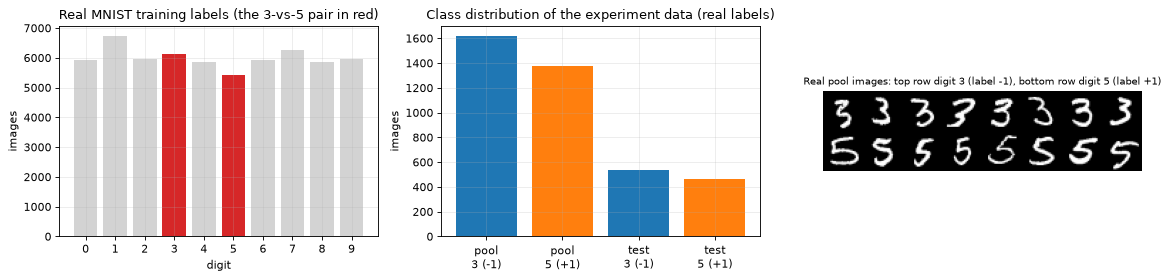

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
cnt = np.bincount(ytr_all, minlength=10)
ax[0].bar(range(10), cnt, color=["tab:red" if d in DIGITS else "lightgrey" for d in range(10)])
ax[0].set_xticks(range(10)); ax[0].set_title("Real MNIST training labels (the 3-vs-5 pair in red)"); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images")
ax[1].bar([f"pool\n{DIGITS[0]} (-1)", f"pool\n{DIGITS[1]} (+1)", f"test\n{DIGITS[0]} (-1)", f"test\n{DIGITS[1]} (+1)"],
          [(yp < 0).sum(), (yp > 0).sum(), (yt < 0).sum(), (yt > 0).sum()], color=["tab:blue", "tab:orange"] * 2)
ax[1].set_title("Class distribution of the experiment data (real labels)"); ax[1].set_ylabel("images")
ax[2].axis("off")
sub = ax[2].inset_axes([0, 0, 1, 1]); sub.axis("off")
tile = np.zeros((2 * 28, 8 * 28))
for r, d in enumerate(DIGITS):
    idx = np.where(dp == d)[0][:8]
    for c, i in enumerate(idx):
        tile[r * 28:(r + 1) * 28, c * 28:(c + 1) * 28] = Xp[i].reshape(28, 28)
sub.imshow(tile, cmap="gray"); sub.set_title(f"Real pool images: top row digit {DIGITS[0]} (label -1), bottom row digit {DIGITS[1]} (label +1)", fontsize=9)
plt.tight_layout(); plt.show()

PCA (pool) explained variance ratio: [0.123 0.081]


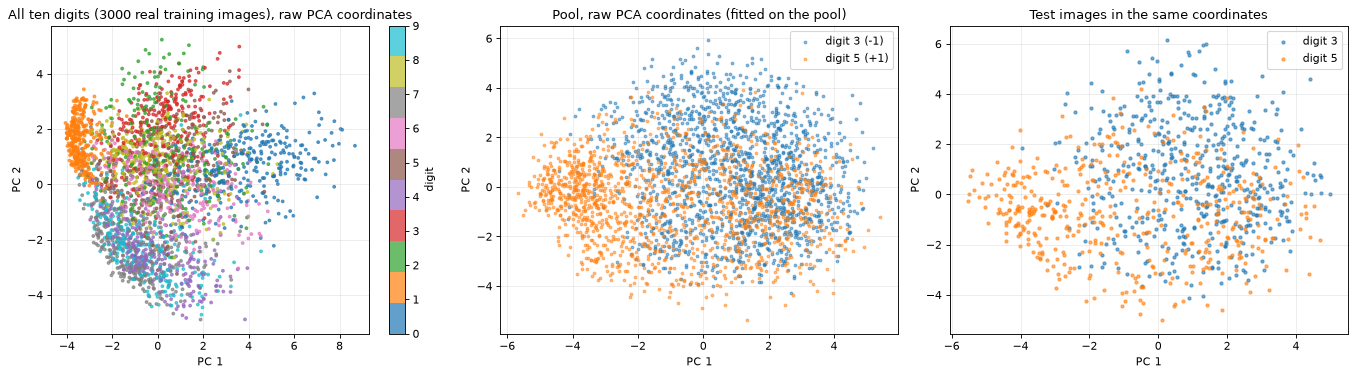

Angle-scaled [0, pi] scatter: NOT_APPLICABLE here. The algorithm loads the data as quantum-state amplitudes (qRAM, paper eqs. 10-11), not as rotation angles, so no [0, pi] rescaling is used.


In [6]:
# 2-D scatter of REAL observations coloured by their ground-truth label. PCA is fitted on the training images only.
pca_ctx = PCA(n_components=2, random_state=SEED).fit(Xtr_all[rs.choice(len(Xtr_all), 8000, replace=False)] / 255.0)   # CHOICE: 8000 training images
ctx_idx = rs.choice(len(Xtr_all), 3000, replace=False)
Zc = pca_ctx.transform(Xtr_all[ctx_idx] / 255.0)
pca2 = PCA(n_components=2, random_state=SEED).fit(Xp)                      # fitted on the pool (training split) of the pair
Zp, Zt = pca2.transform(Xp), pca2.transform(Xt)
print("PCA (pool) explained variance ratio:", np.round(pca2.explained_variance_ratio_, 3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sc = ax[0].scatter(Zc[:, 0], Zc[:, 1], c=ytr_all[ctx_idx], cmap="tab10", s=6, alpha=0.7)
ax[0].set_title("All ten digits (3000 real training images), raw PCA coordinates"); plt.colorbar(sc, ax=ax[0], label="digit")
for lab, col, nm in [(-1, "tab:blue", f"digit {DIGITS[0]} (-1)"), (1, "tab:orange", f"digit {DIGITS[1]} (+1)")]:
    ax[1].scatter(Zp[yp == lab, 0], Zp[yp == lab, 1], s=6, alpha=0.5, c=col, label=nm)
ax[1].set_title("Pool, raw PCA coordinates (fitted on the pool)"); ax[1].legend()
for lab, col, nm in [(-1, "tab:blue", f"digit {DIGITS[0]}"), (1, "tab:orange", f"digit {DIGITS[1]}")]:
    ax[2].scatter(Zt[yt == lab, 0], Zt[yt == lab, 1], s=8, alpha=0.6, c=col, label=nm)
ax[2].set_title("Test images in the same coordinates"); ax[2].legend()
for a in ax: a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()
print("Angle-scaled [0, pi] scatter: NOT_APPLICABLE here. The algorithm loads the data as quantum-state amplitudes (qRAM, paper eqs. 10-11), "
      "not as rotation angles, so no [0, pi] rescaling is used.")

## 2. The classical building blocks: least-squares SVM, class probability and informativeness

Paper eq. (9) solves the least-squares SVM with the linear system

$$F\begin{pmatrix} b\\ \vec\alpha\end{pmatrix}=\begin{pmatrix}0 & \vec 1^{T}\\ \vec 1 & K+\gamma^{-1}\mathbb 1\end{pmatrix}\begin{pmatrix} b\\ \vec\alpha\end{pmatrix}=\begin{pmatrix}0\\ \vec y\end{pmatrix},\qquad \vec w=\sum_i\alpha_i\vec x_i,\quad f(\vec x)=\vec w\cdot\vec x+b .$$

*Informativeness* (eq. 2) of a candidate x is $I(x)=P_c(x)\,|\vec w_{n+1}|$, where $\vec w_{n+1}$ is the weight vector after x has been added
with class label c. The helper below evaluates it for **all candidates at once** by a Schur-complement (block inverse) update of
$F^{-1}$, so that adding one candidate never re-solves the system. A cell asserts that the update equals a full re-solve.
`informativeness` returns the expected value over both classes (main rule) and the single predicted-class product (ablation).

In [7]:
def lssvm_fit(X, y, reg=REG):
    """Least-squares SVM of eq. (9), linear kernel. Returns F^-1, b, alpha."""
    n = len(X)
    F = np.zeros((n + 1, n + 1)); F[0, 1:] = 1; F[1:, 0] = 1; F[1:, 1:] = X @ X.T + reg * np.eye(n)
    Finv = np.linalg.inv(F)
    sol = Finv @ np.r_[0.0, y]
    return Finv, sol[0], sol[1:]

def class_probability(f, a=A_SCALE):
    """P(class +1 | x) = sigmoid(a f). f = +-1 (the margin hyperplanes) gives 0.8, the paper's membership threshold."""
    return 1.0 / (1.0 + np.exp(-a * f))

def informativeness(Finv, b, alpha, Xl, yl, Xc, reg=REG):
    """Eq. (2) for every row of Xc via a Schur-complement update of F^-1.
    Returns (expected informativeness, predicted-class informativeness, P(+1), |w+|, |w-|, f)."""
    w = alpha @ Xl
    f = Xc @ w + b
    u = np.concatenate([np.ones((len(Xc), 1)), Xc @ Xl.T], axis=1)       # new column of the enlarged F (without its diagonal)
    Fi_y = Finv @ np.r_[0.0, yl]
    Fi_u = u @ Finv
    s = (Xc * Xc).sum(1) + reg - (Fi_u * u).sum(1)                       # Schur complement
    Kl = Xl @ Xl.T; kx = u[:, 1:]; xx = (Xc * Xc).sum(1)
    def wnorm(c):
        znew = (c - u @ Fi_y) / s
        zo = (Fi_y[None, :] - Fi_u * znew[:, None])[:, 1:]               # alpha_1..alpha_n after the update
        w2 = ((zo @ Kl) * zo).sum(1) + 2 * znew * (zo * kx).sum(1) + znew ** 2 * xx
        return np.sqrt(np.maximum(w2, 0.0))
    Pp = class_probability(f)
    wp, wm = wnorm(1.0), wnorm(-1.0)
    expected = Pp * wp + (1 - Pp) * wm
    predicted = np.maximum(Pp, 1 - Pp) * np.where(f >= 0, wp, wm)
    return expected, predicted, Pp, wp, wm, f

# ---- assertion: the Schur update equals re-solving the enlarged system
rs0 = np.random.default_rng(SEED)
lab0 = np.r_[rs0.permutation(np.where(yp > 0)[0])[:5], rs0.permutation(np.where(yp < 0)[0])[:5]]
Finv0, b0, al0 = lssvm_fit(Xp[lab0], yp[lab0])
cand0 = rs0.choice(np.setdiff1d(np.arange(len(Xp)), lab0), 6, replace=False)
exp0, pred0, Pp0, wp0, wm0, f0 = informativeness(Finv0, b0, al0, Xp[lab0], yp[lab0], Xp[cand0])
for k, ci in enumerate(cand0):
    for c, wref in [(1.0, wp0[k]), (-1.0, wm0[k])]:
        Xn = np.vstack([Xp[lab0], Xp[ci]]); _, _, aln = lssvm_fit(Xn, np.r_[yp[lab0], c])
        assert np.isclose(np.linalg.norm(aln @ Xn), wref, rtol=1e-8), (k, c)
print("Schur-complement informativeness == full re-solve of eq. (9) for", len(cand0), "candidates and both labels  [assertion passed]")
print("training accuracy of the 10-point LS-SVM:", np.mean(np.sign(Xp[lab0] @ (al0 @ Xp[lab0]) + b0) == yp[lab0]),
      "| test accuracy:", round(float(np.mean(np.sign(Xt @ (al0 @ Xp[lab0]) + b0) == yt)), 3))
print("example candidates: f =", np.round(f0, 2), "\n P(+1) =", np.round(Pp0, 2), "\n expected informativeness =", np.round(exp0, 3))

Schur-complement informativeness == full re-solve of eq. (9) for 6 candidates and both labels  [assertion passed]
training accuracy of the 10-point LS-SVM: 1.0 | test accuracy: 0.676
example candidates: f = [ 0.38  1.13  0.92 -0.26 -0.42  0.68] 
 P(+1) = [0.63 0.83 0.78 0.41 0.36 0.72] 
 expected informativeness = [0.515 0.52  0.52  0.529 0.52  0.521]


## 3. Quantum Circuit Architecture

What the paper's algorithm asks a quantum computer to do, per candidate point, and what is simulated here:

| Paper step | Circuit | In this notebook |
|---|---|---|
| States $|\tilde u\rangle,|\tilde x\rangle$ (eqs. 10-11) loaded from a qRAM | amplitude loading | `StatePreparation` of the real vectors (generic loader, no qRAM) |
| Swap test (eqs. 12-13): $P=\tfrac12(1-\langle\tilde u|\tilde x\rangle)$ | $H$, controlled loaders, $H$ on an ancilla | **drawn and executed** (6 qubits) |
| Amplitude estimation of $\sqrt P$ (Sec. IV A) | Grover operator $Q=A S_0 A^\dagger S_\chi$, controlled $Q^{2^j}$, inverse QFT | **drawn and executed** (swap-test $A$, evaluation qubits M = 3, 4) |
| Amplitude amplification of the top-1/C points (Sec. V, $O(\sqrt C)$) | Grover iterations on an index register | **drawn and executed** (6 qubits, real informativeness scores) |
| Solving eq. (9) with HHL / Hamiltonian simulation, $\vec w=A|b,\alpha\rangle$ by Chebyshev walks | phase estimation, quantum walks | **not simulated** (exact linear algebra supplies $|b,\alpha\rangle$); assumption listed in the table of section "What follows the paper" |

None of these circuits has trainable parameters: the algorithm is not variational. The only "parameters" are the amplitudes of the
loaded states, which are computed from the real data, so the trainable-parameter count printed below is 0 and the number of loaded
amplitudes is given instead. The small instance below uses **the first two principal components of real MNIST images** (7 labelled
digits as training points, 1 test digit as the query), so that the state register has 3 + 2 qubits.

In [8]:
# ------------------------------------------------------------------ small REAL instance for the circuits
N_L, M_L = 7, 2                                   # labelled points, feature dimensions (PCA components)
rs3 = np.random.default_rng(SEED + 3)
z_scale = Zp.std(axis=0)                          # train-only standardisation of the 2 PCA coordinates
pos = rs3.permutation(np.where(yp > 0)[0])[:4]; neg = rs3.permutation(np.where(yp < 0)[0])[:3]
idx_L = np.r_[pos, neg]
XL, yL = Zp[idx_L] / z_scale, yp[idx_L]
Finv_s, b_s, al_s = lssvm_fit(XL, yL, reg=REG)
w_s = al_s @ XL

def small_states(x):
    """Padded amplitude vectors of |u~> (eq. 10) and |x~> (eq. 11); index = j + 4 k (j: coordinate register, k: sample register)."""
    u = np.zeros((8, 4)); u[0, 0] = b_s
    xt = np.zeros((8, 4)); xt[0, 0] = 1.0
    for k in range(N_L):
        u[k + 1, 1:1 + M_L] = al_s[k] * XL[k]       # alpha_k |x_k| |k> |x_k>  -> amplitude alpha_k x_kj
        xt[k + 1, 1:1 + M_L] = x                    # |x| |k> |x>               -> amplitude x_j
    u, xt = u.ravel(), xt.ravel()
    return u, xt, np.linalg.norm(u), np.linalg.norm(xt)

def swap_test_circuit(x):
    u, xt, nu, nx = small_states(x)
    A = QuantumCircuit(6, name="A")               # q0 = swap-test ancilla, q1..q5 = state register (2 + 3 qubits)
    A.h(0)
    A.append(StatePreparation(u / nu, label="|u~>").control(1, ctrl_state=0), range(6))
    A.append(StatePreparation(xt / nx, label="|x~>").control(1, ctrl_state=1), range(6))
    A.h(0)
    return A, nu, nx

# query: a real test image whose decision value is moderate
zq_all = Zt / z_scale
fq_all = zq_all @ w_s + b_s
q_i = int(np.argsort(np.abs(fq_all - 0.3))[0])
xq = zq_all[q_i]
A_swap, NU, NX = swap_test_circuit(xq)
P_circ = Statevector(A_swap).probabilities([0])[1]
f_q = float(xq @ w_s + b_s)
P_formula = 0.5 * (1 - f_q / (NU * NX))
print(f"query test image #{q_i} (true label {int(yt[q_i]):+d}); f(x) = w.x + b = {f_q:.4f}")
print(f"swap-test probability P(ancilla=1): circuit {P_circ:.10f}   formula 1/2 (1 - (w.x+b)/(|u||x|)) = {P_formula:.10f}")
assert abs(P_circ - P_formula) < 1e-9
print("[assertion passed] eq. (12)-(13) reproduced by the circuit")

query test image #679 (true label +1); f(x) = w.x + b = 0.3015
swap-test probability P(ancilla=1): circuit 0.4483440689   formula 1/2 (1 - (w.x+b)/(|u||x|)) = 0.4483440689
[assertion passed] eq. (12)-(13) reproduced by the circuit


Swap-test circuit A (the circuit that is executed). Controlled boxes load |u~> (ancilla 0) and |x~> (ancilla 1):


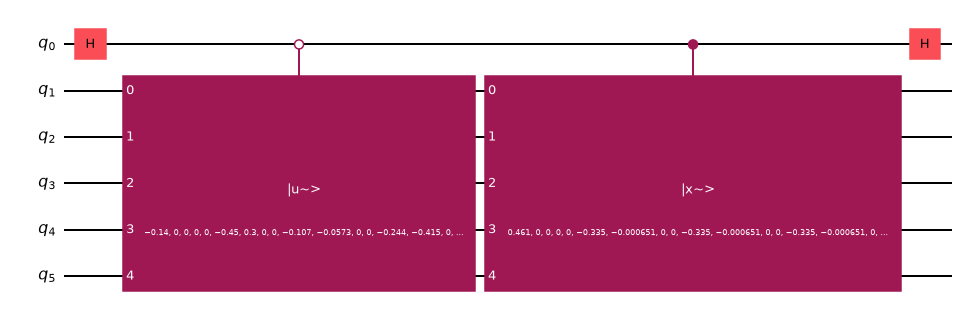

A: qubits 6 | logical depth 4 | depth after transpile to {u,cx}: 820 (436 CX) | trainable parameters 0 | loaded amplitudes: 2 x 32 real numbers from the data


In [9]:
print("Swap-test circuit A (the circuit that is executed). Controlled boxes load |u~> (ancilla 0) and |x~> (ancilla 1):")
display(A_swap.draw("mpl", fold=-1, scale=0.9))
tA = transpile(A_swap, basis_gates=["u", "cx"], optimization_level=1)
print(f"A: qubits {A_swap.num_qubits} | logical depth {A_swap.depth()} | depth after transpile to {{u,cx}}: {tA.depth()} "
      f"({tA.count_ops().get('cx', 0)} CX) | trainable parameters 0 | loaded amplitudes: 2 x {2**5} real numbers from the data")

Q has the eigenphases +-theta/pi with sin^2(theta) = P:  theta/pi = 0.233528  [assertion passed]


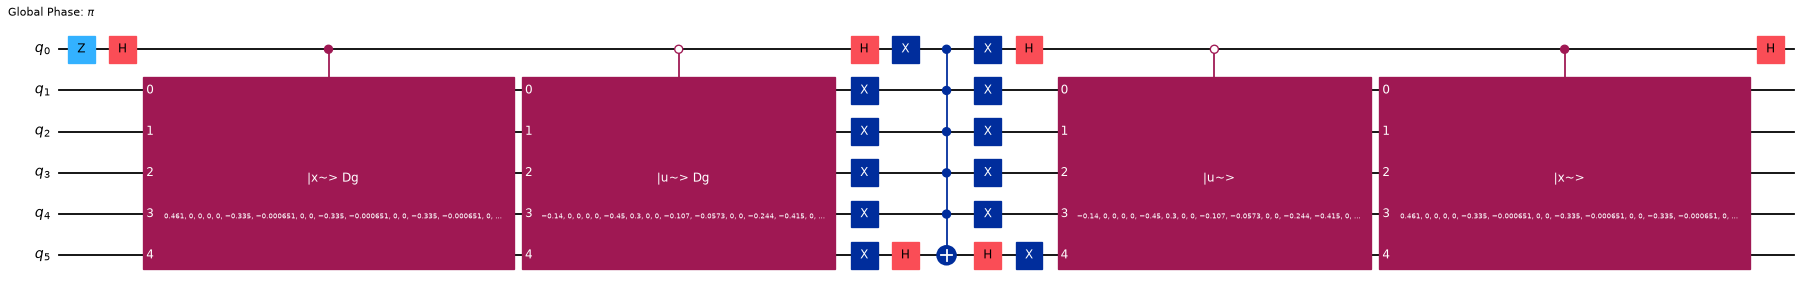

Q: qubits 6 | depth after transpile 1769 (956 CX) | trainable parameters 0


In [10]:
# Grover operator Q = A S_0 A^dagger S_chi for the swap test (good state: ancilla = 1, i.e. the |-> outcome of the paper)
oracle_flag = QuantumCircuit(6); oracle_flag.z(0)
Q_swap = grover_operator(oracle_flag, state_preparation=A_swap)
U_Q = Operator(Q_swap).data
theta_a = math.asin(math.sqrt(P_circ))
ph = np.sort((np.angle(np.linalg.eigvals(U_Q)) / (2 * np.pi)) % 1)
assert np.isclose(ph, theta_a / np.pi, atol=1e-8).any() and np.isclose(ph, 1 - theta_a / np.pi, atol=1e-8).any()
print(f"Q has the eigenphases +-theta/pi with sin^2(theta) = P:  theta/pi = {theta_a/np.pi:.6f}  [assertion passed]")
display(Q_swap.draw("mpl", fold=-1, scale=0.8))
tQ = transpile(Q_swap, basis_gates=["u", "cx"], optimization_level=1)
print(f"Q: qubits {Q_swap.num_qubits} | depth after transpile {tQ.depth()} ({tQ.count_ops().get('cx', 0)} CX) | trainable parameters 0")

[assertion passed] controlled block == control 0: identity, control 1: the executed Grover circuit Q


M = 3 evaluation qubits: circuit distribution == analytic Dirichlet-kernel formula (max diff 4.6e-14); most likely y = 2 -> amplitude estimate sqrt(a~) = 0.7071 (true sqrt(P) = 0.6696)  [0.1s]
M = 4 evaluation qubits: circuit distribution == analytic Dirichlet-kernel formula (max diff 1.3e-13); most likely y = 4 -> amplitude estimate sqrt(a~) = 0.7071 (true sqrt(P) = 0.6696)  [0.1s]
Quantum amplitude estimation circuit, M = 3 (each c-Q^k box is the controlled k-fold application of the Grover circuit above):


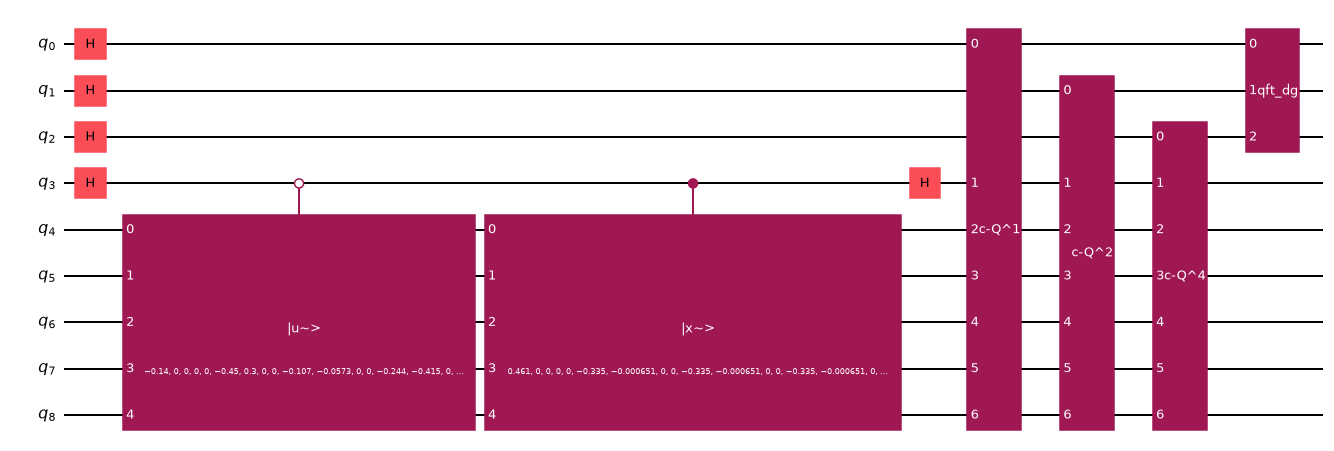

QAE (M=3): qubits 9 | logical depth 8 (each controlled power = one block) | trainable parameters 0 | cost = 7 applications of Q = 14 calls of A or A^dagger (+1)


In [11]:
# ---- canonical amplitude estimation (Brassard et al.): H on M evaluation qubits, controlled Q^(2^j), inverse QFT.
def controlled_block(Uk):
    """Matrix of 'controlled-Uk' on [control, data...] (control = least significant qubit)."""
    d = Uk.shape[0]; B = np.zeros((2 * d, 2 * d), complex)
    B[0::2, 0::2] = np.eye(d); B[1::2, 1::2] = Uk
    return B

def qae_circuit_blocks(A, U, M, nq):
    qc = QuantumCircuit(nq + M, name=f"QAE_M{M}")
    qc.compose(A, list(range(M, M + nq)), inplace=True)
    qc.h(range(M))
    for j in range(M):
        qc.append(UnitaryGate(controlled_block(np.linalg.matrix_power(U, 2 ** j)), label=f"c-Q^{2**j}"), [j] + list(range(M, M + nq)))
    qc.append(QFTGate(M).inverse(), range(M))
    return qc

def qae_dist(a, M):
    """Exact output distribution of canonical QAE (vectorised): y in 0..2^M-1, estimate sin^2(pi y / 2^M)."""
    N = 2 ** M; y = np.arange(N); th = math.asin(math.sqrt(a)) / math.pi
    def D2(d):
        den = N * np.sin(np.pi * d)
        safe = np.where(np.abs(den) < 1e-12, 1.0, den)
        return np.where(np.abs(den) < 1e-12, 1.0, np.sin(np.pi * N * d) / safe) ** 2
    return 0.5 * (D2(th - y / N) + D2(1 - th - y / N))

# assertion 1: the controlled block is exactly "do nothing / apply the real circuit Q"
psi = Statevector(np.random.default_rng(1).normal(size=64) + 1j * np.random.default_rng(2).normal(size=64)); psi = Statevector(psi.data / np.linalg.norm(psi.data))
B1 = controlled_block(U_Q)
v1 = np.zeros(128, complex); v1[1::2] = psi.data; v0 = np.zeros(128, complex); v0[0::2] = psi.data
assert np.allclose((B1 @ v1)[1::2], psi.evolve(Q_swap).data) and np.allclose((B1 @ v0)[0::2], psi.data)
print("[assertion passed] controlled block == control 0: identity, control 1: the executed Grover circuit Q")

QAE_DEMO = {}
for M in (3, 4):
    t0 = time.time()
    qc = qae_circuit_blocks(A_swap, U_Q, M, 6)
    pr = Statevector(qc).probabilities(list(range(M)))
    pa = qae_dist(P_circ, M)
    QAE_DEMO[M] = (qc, pr)
    assert np.allclose(pr, pa, atol=1e-9)
    print(f"M = {M} evaluation qubits: circuit distribution == analytic Dirichlet-kernel formula (max diff {np.abs(pr - pa).max():.1e}); "
          f"most likely y = {pr.argmax()} -> amplitude estimate sqrt(a~) = {math.sin(math.pi * pr.argmax() / 2**M):.4f} (true sqrt(P) = {math.sqrt(P_circ):.4f})  [{time.time()-t0:.1f}s]")
print("Quantum amplitude estimation circuit, M = 3 (each c-Q^k box is the controlled k-fold application of the Grover circuit above):")
display(QAE_DEMO[3][0].draw("mpl", fold=-1, scale=0.9))
qc3 = QAE_DEMO[3][0]
print(f"QAE (M=3): qubits {qc3.num_qubits} | logical depth {qc3.depth()} (each controlled power = one block) | trainable parameters 0 | "
      f"cost = {2**3 - 1} applications of Q = {2*(2**3-1)} calls of A or A^dagger (+1)")

In [12]:
# ---- gate-level cross-check of the QAE formula: A = Ry on one qubit, controlled powers of the real Grover circuit, M = 3..5
def qae_gatelevel(a, M):
    th = math.asin(math.sqrt(a))
    A1 = QuantumCircuit(1); A1.ry(2 * th, 0)                          # sin^2(theta) = a on |1>
    o1 = QuantumCircuit(1); o1.z(0)
    Q1 = grover_operator(o1, state_preparation=A1)
    qc = QuantumCircuit(M + 1); qc.compose(A1, [M], inplace=True); qc.h(range(M))
    for j in range(M):
        qc.append(Q1.power(2 ** j).to_gate().control(1), [j, M])
    qc.append(QFTGate(M).inverse(), range(M))
    return qc
for M in (3, 4, 5):
    for a in (0.12, P_circ):
        pr = Statevector(qae_gatelevel(a, M)).probabilities(list(range(M)))
        assert np.allclose(pr, qae_dist(a, M), atol=1e-9)
print("[assertion passed] gate-level QAE (real controlled-Grover gates, M = 3, 4, 5) == analytic distribution used for all scaling plots")

[assertion passed] gate-level QAE (real controlled-Grover gates, M = 3, 4, 5) == analytic distribution used for all scaling plots


N = 64 real candidates, top 1/C with C = 8: 8 marked; Grover iterations r = 2


success probability: circuit 0.945312 | sin^2((2r+1) theta) = 0.945312 | classical single draw: 0.125


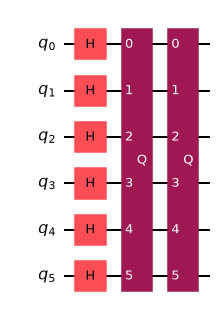

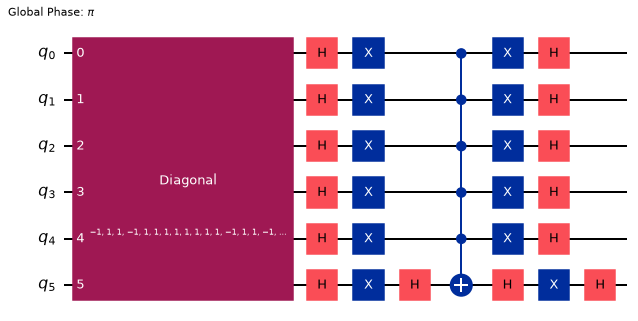

Grover operator: qubits 6 | depth after transpile 220 | trainable parameters 0 | amplitude-amplification circuit logical depth 3


In [13]:
# ---- amplitude amplification (Grover) on REAL informativeness scores: find one of the top-1/C candidates among N = 64
rs4 = np.random.default_rng(SEED + 4)
NQ_G = 6; N_G = 2 ** NQ_G
cand_G = rs4.choice(np.setdiff1d(np.arange(len(Xp)), lab0), N_G, replace=False)
score_G = informativeness(Finv0, b0, al0, Xp[lab0], yp[lab0], Xp[cand_G])[0]      # real informativeness of 64 real images
C_AMP = 8
M_G = N_G // C_AMP
marked = np.sort(np.argsort(-score_G)[:M_G])                                       # the top 1/C quantile (threshold found by bisection + QAE in the paper)
signs = np.ones(N_G); signs[marked] = -1
orc = QuantumCircuit(NQ_G); orc.append(DiagonalGate(list(signs)), range(NQ_G))
Qg = grover_operator(orc)
theta_g = math.asin(math.sqrt(M_G / N_G)); r_opt = int(math.floor(math.pi / (4 * theta_g)))
qg = QuantumCircuit(NQ_G, name="amplitude_amplification"); qg.h(range(NQ_G))
for _ in range(r_opt): qg.append(Qg.to_gate(label="Q"), range(NQ_G))
p_succ = Statevector(qg).probabilities()[marked].sum()
print(f"N = {N_G} real candidates, top 1/C with C = {C_AMP}: {M_G} marked; Grover iterations r = {r_opt}")
print(f"success probability: circuit {p_succ:.6f} | sin^2((2r+1) theta) = {math.sin((2*r_opt+1)*theta_g)**2:.6f} | classical single draw: {M_G/N_G:.3f}")
assert abs(p_succ - math.sin((2 * r_opt + 1) * theta_g) ** 2) < 1e-9
display(qg.draw("mpl", fold=-1, scale=0.9))
display(Qg.draw("mpl", fold=-1, scale=0.9))
tg = transpile(Qg, basis_gates=["u", "cx"], optimization_level=1)
print(f"Grover operator: qubits {Qg.num_qubits} | depth after transpile {tg.depth()} | trainable parameters 0 | amplitude-amplification circuit logical depth {qg.depth()}")

In [14]:
summary = pd.DataFrame([
    ["swap test A (eqs. 10-13)", A_swap.num_qubits, tA.depth(), 0, "2 x 32 loaded amplitudes (real data)"],
    ["Grover operator Q of A", Q_swap.num_qubits, tQ.depth(), 0, "-"],
    ["QAE, M = 3", qc3.num_qubits, qc3.depth(), 0, f"{2**3-1} x Q"],
    ["QAE, M = 4", QAE_DEMO[4][0].num_qubits, QAE_DEMO[4][0].depth(), 0, f"{2**4-1} x Q"],
    ["amplitude amplification (N=64, C=8)", qg.num_qubits, qg.depth(), 0, f"{r_opt} x Q_Grover"],
], columns=["circuit", "qubits", "depth", "trainable params", "note"])
print(summary.to_string(index=False))
print("\nAssumptions where the paper omits circuit details: (1) the qRAM is replaced by generic amplitude loaders (cost O(2^qubits) gates, not O(log n)); "
      "(2) the HHL / Chebyshev subroutines that would prepare |b, alpha> and |w> are replaced by their exact classical output; "
      "(3) 'good' state = ancilla |1>, i.e. the |-> outcome of the swap test (P = (1 - <u|x>)/2); (4) the real, not complex, amplitudes of the data are used.")

                            circuit  qubits  depth  trainable params                                 note
           swap test A (eqs. 10-13)       6    820                 0 2 x 32 loaded amplitudes (real data)
             Grover operator Q of A       6   1769                 0                                    -
                         QAE, M = 3       9      8                 0                                7 x Q
                         QAE, M = 4      10      9                 0                               15 x Q
amplitude amplification (N=64, C=8)       6      3                 0                         2 x Q_Grover

Assumptions where the paper omits circuit details: (1) the qRAM is replaced by generic amplitude loaders (cost O(2^qubits) gates, not O(log n)); (2) the HHL / Chebyshev subroutines that would prepare |b, alpha> and |w> are replaced by their exact classical output; (3) 'good' state = ancilla |1>, i.e. the |-> outcome of the swap test (P = (1 - <u|x>)/2); (4) the

## 4. Checking the paper's numerical claims

The paper reports no experiment, so each claim below is a mathematical statement turned into a measurement. A helper collects one row
per claim for the final verdict table. Verdict words: **reproduced** (within 2 points / 0.02, or fitted exponent within 0.15 of the
claim), **not reached** (measured outside tolerance), **cannot be checked** (needs qRAM / fault-tolerant hardware or has no
numerical content). Vectorised formulas used here (the QAE distribution, the Grover success formula) were asserted equal to the
executed circuits in section 3.

In [15]:
CLAIMS = []
def claim(cid, text, paper, measured, verdict, note=""):
    CLAIMS.append(dict(id=cid, claim=text, paper=paper, notebook=measured, verdict=verdict, note=note))
    print(f"[{cid}] {text}\n      paper: {paper} | this notebook: {measured} -> {verdict.upper()}" + (f"  ({note})" if note else ""))

def loglog_slope(x, y):
    return float(np.polyfit(np.log2(np.asarray(x, float)), np.log2(np.asarray(y, float)), 1)[0])

def within(slope, target, tol=0.15):
    return "reproduced" if abs(slope - target) <= tol else "not reached"

### 4.1 The swap test (eqs. 12-13) and the classification rule

Paper eq. (12): $P=\tfrac12(1-\langle\tilde u|\tilde x\rangle)$, where $\langle\tilde u|\tilde x\rangle=(\vec w\cdot\vec x+b)/(|\tilde u||\tilde x|)$.
The paper then says "If $P\ge 1/2$, $y(\vec x)=1$, otherwise $y(\vec x)=-1$". With eq. (12) and the SVM convention
$y=\mathrm{sgn}(\vec w\cdot\vec x+b)$ the two statements cannot both hold: a positive $\vec w\cdot\vec x+b$ gives $P<1/2$. The circuit decides.

In [16]:
K_Q = 12 if FAST_MODE else 30
q_ids = np.random.default_rng(SEED + 5).choice(len(Xt), K_Q, replace=False)
rows = []
for i in q_ids:
    A_i, nu, nx = swap_test_circuit(zq_all[i])
    P_i = Statevector(A_i).probabilities([0])[1]
    f_i = float(zq_all[i] @ w_s + b_s)
    rows.append((int(i), int(yt[i]), f_i, P_i, 0.5 * (1 - f_i / (nu * nx))))
sw = pd.DataFrame(rows, columns=["test_image", "true_label", "f=w.x+b", "P_circuit", "P_eq12"])
max_err = float(np.abs(sw.P_circuit - sw.P_eq12).max())
pred_paper = np.where(sw.P_circuit >= 0.5, 1, -1)      # rule as printed in Sec. III of the paper
pred_fixed = np.where(sw.P_circuit < 0.5, 1, -1)       # rule implied by eq. (12)
svm_label = np.sign(sw["f=w.x+b"])
agree_paper, agree_fixed = float(np.mean(pred_paper == svm_label)), float(np.mean(pred_fixed == svm_label))
print(sw.head(6).round(4).to_string(index=False))
print(f"\n{K_Q} real test images: max |P_circuit - P_eq12| = {max_err:.2e}")
print(f"agreement with sgn(w.x+b):  rule 'P >= 1/2 -> +1' (as printed) {agree_paper:.2f}   |   rule 'P < 1/2 -> +1' (implied by eq. 12) {agree_fixed:.2f}")
claim("C1", "swap-test probability P = (1 - <u|x>)/2 (eq. 12)", "exact identity", f"max abs diff {max_err:.1e} over {K_Q} circuits",
      "reproduced" if max_err < 1e-9 else "not reached")
claim("C2", "classification rule 'P >= 1/2 -> y = +1' (Sec. III)", "rule agrees with the SVM", f"agreement {agree_paper:.2f} (the opposite rule: {agree_fixed:.2f})",
      "reproduced" if agree_paper >= 0.98 else "not reached", "sign convention inconsistent with eq. 12; harmless once flipped")

 test_image  true_label  f=w.x+b  P_circuit  P_eq12
        940           1   0.3554     0.4714  0.4714
        197           1  -1.1495     0.5757  0.5757
        529           1   0.9790     0.4259  0.4259
        835          -1   0.6713     0.4283  0.4283
        177          -1   0.2367     0.4726  0.4726
        744           1  -1.1674     0.6045  0.6045

30 real test images: max |P_circuit - P_eq12| = 1.33e-15
agreement with sgn(w.x+b):  rule 'P >= 1/2 -> +1' (as printed) 0.00   |   rule 'P < 1/2 -> +1' (implied by eq. 12) 1.00
[C1] swap-test probability P = (1 - <u|x>)/2 (eq. 12)
      paper: exact identity | this notebook: max abs diff 1.3e-15 over 30 circuits -> REPRODUCED
[C2] classification rule 'P >= 1/2 -> y = +1' (Sec. III)
      paper: rule agrees with the SVM | this notebook: agreement 0.00 (the opposite rule: 1.00) -> NOT REACHED  (sign convention inconsistent with eq. 12; harmless once flipped)


### 4.2 Amplitude estimation: precision $O(\epsilon^{-1})$ instead of $O(\epsilon^{-2})$ (Sec. IV A, theorem 6)

The paper replaces repeated measurement of the swap test (cost $O(\epsilon^{-2})$) by amplitude estimation (cost $O(\epsilon^{-1})$) to
read the amplitude $\sqrt P$. Below, the **exact** output distribution of the canonical QAE circuit (asserted equal to the executed
circuits in section 3) gives the median amplitude error as a function of the number of calls of the state-preparation circuit $A$.
Classical baselines on the same budget: $N$ repeated swap-test measurements (exact binomial distribution) and the
"dequantised" estimator of appendix E, lemma 3 (sample $i\sim|\tilde u_i|^2$, average $\tilde x_i/\tilde u_i$; Monte Carlo).

 M  calls_of_A  QAE_median_amp_error  swap_test_shots_median_amp_error
 1           3               0.43198                           0.21606
 2           7               0.14447                           0.09664
 3          15               0.09800                           0.05937
 4          31               0.02268                           0.04769
 5          63               0.01690                           0.03076
 6         127               0.00652                           0.02311
 7         255               0.00387                           0.01607
 8         511               0.00219                           0.01164
 9        1023               0.00226                           0.00837
10        2047               0.00024                           0.00585
11        4095               0.00024                           0.00410
12        8191               0.00024                           0.00293

fitted exponents of error vs calls (M >= 3): QAE -0.97 (theory -1) | repeate

Monte Carlo (300 repeats): swap-test shots exponent -0.47 | dequantised sampling estimator exponent -0.53 (both expected -1/2)
theorem 6: smallest success probability over M = 2..10 and 25 values of a: 0.8106  (claimed >= 8/pi^2 = 0.8106)


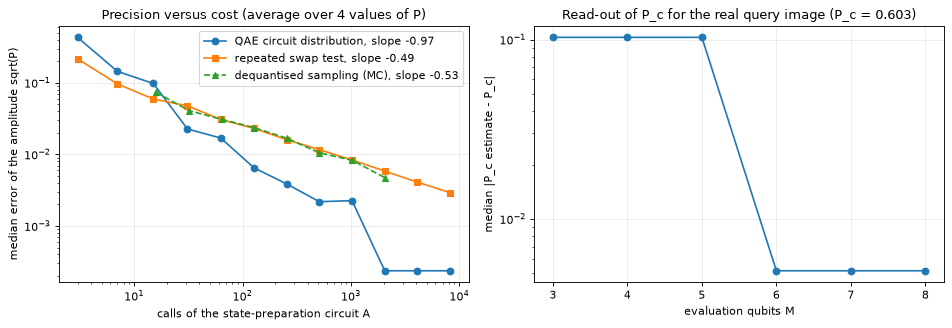

[C3] amplitude estimation reads the amplitude with cost O(1/eps) (classical swap test O(1/eps^2))
      paper: exponent -1 versus -2 in the cost, i.e. -1 versus -1/2 in the error per call | this notebook: QAE -0.97, swap-test shots -0.49, dequantised sampling -0.53 -> REPRODUCED
[C4] theorem 6: QAE error bound holds with probability >= 8/pi^2
      paper: 0.8106 | this notebook: min over a, M = 0.8106 -> REPRODUCED


In [17]:
def wmedian(values, weights):
    o = np.argsort(values); v, w = np.asarray(values)[o], np.asarray(weights)[o]
    return float(v[np.searchsorted(np.cumsum(w), 0.5 * w.sum())])

A_LIST = [0.1, 0.3, float(P_circ), 0.7]                       # success probabilities used (one of them is the real swap-test value)
rows = []
for M in QAE_MS:
    N = 2 ** M; calls = 2 * (N - 1) + 1                        # Q uses A and A^dagger once each: 2(2^M - 1) + 1 calls of A
    e_q, e_c = [], []
    for a in A_LIST:
        pdist = qae_dist(a, M)
        est_amp = np.sin(np.pi * np.arange(N) / N)
        e_q.append(wmedian(np.abs(est_amp - math.sqrt(a)), pdist))
        k = np.arange(calls + 1); pk = stats.binom.pmf(k, calls, a)
        e_c.append(wmedian(np.abs(np.sqrt(k / calls) - math.sqrt(a)), pk))
    rows.append((M, calls, np.median(e_q), np.median(e_c)))
qs = pd.DataFrame(rows, columns=["M", "calls_of_A", "QAE_median_amp_error", "swap_test_shots_median_amp_error"])
print(qs.round(5).to_string(index=False))
s_q = loglog_slope(qs.calls_of_A[2:], qs.QAE_median_amp_error[2:]); s_c = loglog_slope(qs.calls_of_A[2:], qs.swap_test_shots_median_amp_error[2:])
print(f"\nfitted exponents of error vs calls (M >= 3): QAE {s_q:.2f} (theory -1) | repeated swap test {s_c:.2f} (theory -1/2)")

# Monte-Carlo cross-checks of the classical baselines (swap-test shots and the dequantised estimator of lemma 3)
u_vec, x_vec, nu_, nx_ = small_states(xq); u_n, x_n = u_vec / nu_, x_vec / nx_
ov_true = float(u_n @ x_n); a_true = 0.5 * (1 - ov_true)
rmc = np.random.default_rng(SEED + 6); Ns = [2 ** k for k in range(4, 12)]; mc_swap, mc_deq = [], []
pu = u_n ** 2; nz = pu > 1e-12
for N in Ns:
    e1, e2 = [], []
    for _ in range(300):
        P_hat = rmc.binomial(N, a_true) / N
        e1.append(abs(math.sqrt(P_hat) - math.sqrt(a_true)))
        ii = rmc.choice(len(u_n), N, p=pu / pu.sum())
        ov_hat = float(np.mean(x_n[ii] / u_n[ii]))
        e2.append(abs(math.sqrt(max(0.5 * (1 - ov_hat), 0)) - math.sqrt(a_true)))
    mc_swap.append(np.median(e1)); mc_deq.append(np.median(e2))
s_mc1, s_mc2 = loglog_slope(Ns, mc_swap), loglog_slope(Ns, mc_deq)
print(f"Monte Carlo (300 repeats): swap-test shots exponent {s_mc1:.2f} | dequantised sampling estimator exponent {s_mc2:.2f} (both expected -1/2)")

# Theorem 6 (k = 1): P(|a - a~| <= 2 pi sqrt(a(1-a))/J + pi^2/J^2) >= 8/pi^2
worst = 1.0
for M in range(2, 11):
    J = 2 ** M
    for a in np.linspace(0.02, 0.98, 25):
        pdist = qae_dist(a, M); at = np.sin(np.pi * np.arange(J) / J) ** 2
        bound = 2 * np.pi * math.sqrt(a * (1 - a)) / J + np.pi ** 2 / J ** 2
        worst = min(worst, float(pdist[np.abs(at - a) <= bound + 1e-12].sum()))
print(f"theorem 6: smallest success probability over M = 2..10 and 25 values of a: {worst:.4f}  (claimed >= 8/pi^2 = {8/np.pi**2:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].loglog(qs.calls_of_A, qs.QAE_median_amp_error, "o-", label=f"QAE circuit distribution, slope {s_q:.2f}")
ax[0].loglog(qs.calls_of_A, qs.swap_test_shots_median_amp_error, "s-", label=f"repeated swap test, slope {s_c:.2f}")
ax[0].loglog(Ns, mc_deq, "^--", label=f"dequantised sampling (MC), slope {s_mc2:.2f}")
ax[0].set_xlabel("calls of the state-preparation circuit A"); ax[0].set_ylabel("median error of the amplitude sqrt(P)"); ax[0].legend(); ax[0].set_title("Precision versus cost (average over 4 values of P)")
# the P_c read-out pipeline: QAE -> P~ -> f~ = |u||x|(1 - 2P~) -> P_c = sigmoid(ln4 f~)
pc_true = class_probability(f_q); errs = []
for M in range(3, 9):
    pdist = qae_dist(P_circ, M); at = np.sin(np.pi * np.arange(2 ** M) / 2 ** M) ** 2
    pc_hat = class_probability(NU * NX * (1 - 2 * at))
    errs.append(wmedian(np.abs(pc_hat - pc_true), pdist))
ax[1].semilogy(range(3, 9), errs, "o-"); ax[1].set_xlabel("evaluation qubits M"); ax[1].set_ylabel("median |P_c estimate - P_c|")
ax[1].set_title(f"Read-out of P_c for the real query image (P_c = {pc_true:.3f})")
plt.tight_layout(); plt.show()
claim("C3", "amplitude estimation reads the amplitude with cost O(1/eps) (classical swap test O(1/eps^2))", "exponent -1 versus -2 in the cost, i.e. -1 versus -1/2 in the error per call",
      f"QAE {s_q:.2f}, swap-test shots {s_c:.2f}, dequantised sampling {s_mc2:.2f}", "reproduced" if abs(s_q + 1) <= 0.15 and abs(s_c + 0.5) <= 0.15 else "not reached")
claim("C4", "theorem 6: QAE error bound holds with probability >= 8/pi^2", "0.8106", f"min over a, M = {worst:.4f}", "reproduced" if worst >= 8 / np.pi ** 2 - 0.02 else "not reached")

### 4.3 Algorithm 1: the best of $c=O(C\beta)$ uniform draws is in the top-$1/C$ quantile with probability $1-e^{-\beta}$ (eqs. 33-35)

This is checked on **real informativeness values**: the expected informativeness (eq. 2) of every image of the pool under the
10-point initial model. The candidates are drawn uniformly with replacement, the best is kept, and its rank in the whole pool is
checked.

  C  beta  draws_c  failure_rate  bound_exp(-beta)  within_bound
  5   1.0        5        0.3243            0.3679          True
  5   2.0        9        0.1344            0.1353          True
  5   3.0       14        0.0422            0.0498          True
  5   4.0       18        0.0184            0.0183          True
 10   1.0       10        0.3500            0.3679          True
 10   2.0       19        0.1350            0.1353          True
 10   3.0       29        0.0464            0.0498          True
 10   4.0       38        0.0184            0.0183          True
 20   1.0       20        0.3606            0.3679          True
 20   2.0       39        0.1404            0.1353          True
 20   3.0       59        0.0498            0.0498          True
 20   4.0       78        0.0174            0.0183          True
 50   1.0       50        0.3711            0.3679          True
 50   2.0       99        0.1352            0.1353          True
 50   3.0      149       

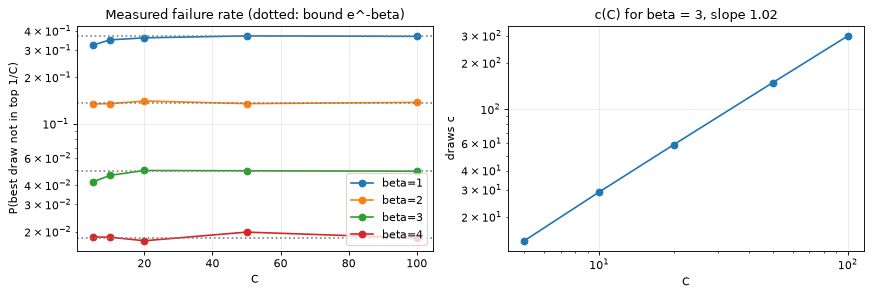

[C5] Algorithm 1: best of c = O(beta C) draws is in the top 1/C quantile with probability >= 1 - exp(-beta)
      paper: failure <= exp(-beta); c = O(beta C) | this notebook: failure within bound in 20/20 settings; c ~ C^1.02, beta^0.99 -> REPRODUCED


In [18]:
score_pool = informativeness(Finv0, b0, al0, Xp[lab0], yp[lab0], Xp)[0]
rank_of = np.empty(len(Xp), int); rank_of[np.argsort(-score_pool)] = np.arange(len(Xp))      # 0 = most informative
rmc = np.random.default_rng(SEED + 7)
rows = []
for C in [5, 10, 20, 50, 100]:
    for beta in [1.0, 2.0, 3.0, 4.0]:
        c = int(math.ceil(beta / -math.log(1 - 1 / C)))
        draws = rmc.integers(0, len(Xp), (MC_TRIALS, c))
        best = draws[np.arange(MC_TRIALS), score_pool[draws].argmax(1)]
        fail = float(np.mean(rank_of[best] >= len(Xp) // C))
        rows.append((C, beta, c, fail, math.exp(-beta), fail <= math.exp(-beta) + 2 * math.sqrt(math.exp(-beta) / MC_TRIALS) + 0.01))
mcres = pd.DataFrame(rows, columns=["C", "beta", "draws_c", "failure_rate", "bound_exp(-beta)", "within_bound"])
print(mcres.round(4).to_string(index=False))
big = mcres[mcres.C >= 10]
sC = loglog_slope(mcres[mcres.beta == 3.0].C, mcres[mcres.beta == 3.0].draws_c); sB = loglog_slope(mcres[mcres.C == 50].beta, mcres[mcres.C == 50].draws_c)
print(f"\nfitted growth of the number of draws: c ~ C^{sC:.2f} (claim 1), c ~ beta^{sB:.2f} (claim 1)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for beta in [1.0, 2.0, 3.0, 4.0]:
    d = mcres[mcres.beta == beta]; ax[0].semilogy(d.C, d.failure_rate, "o-", label=f"beta={beta:g}"); ax[0].axhline(math.exp(-beta), ls=":", c="grey")
ax[0].set_xlabel("C"); ax[0].set_ylabel("P(best draw not in top 1/C)"); ax[0].set_title("Measured failure rate (dotted: bound e^-beta)"); ax[0].legend()
ax[1].loglog(mcres[mcres.beta == 3.0].C, mcres[mcres.beta == 3.0].draws_c, "o-"); ax[1].set_xlabel("C"); ax[1].set_ylabel("draws c"); ax[1].set_title(f"c(C) for beta = 3, slope {sC:.2f}")
plt.tight_layout(); plt.show()
claim("C5", "Algorithm 1: best of c = O(beta C) draws is in the top 1/C quantile with probability >= 1 - exp(-beta)", "failure <= exp(-beta); c = O(beta C)",
      f"failure within bound in {int(mcres.within_bound.sum())}/{len(mcres)} settings; c ~ C^{sC:.2f}, beta^{sB:.2f}",
      "reproduced" if mcres.within_bound.all() and abs(sC - 1) <= 0.15 and abs(sB - 1) <= 0.15 else "not reached")

### 4.4 Amplitude amplification finds the marked points in $O(\sqrt C)$ iterations (Sec. V)

The Grover success formula $\sin^2((2r+1)\theta)$ with $\sin\theta=\sqrt{1/C}$ is asserted against the executed circuit for several
sizes, then the optimal number of iterations is fitted against $C$; a classical search needs $C$ draws.

[assertion passed] Grover success probability sin^2((2r+1) theta) == executed circuit (q = 3..6, C = 2, 4, 8, r = 1..3)
optimal Grover iterations r*(C) for C = 4 ... 16384 grows as C^0.53 (claim 1/2); classical expected draws = C^1; min success probability 0.945


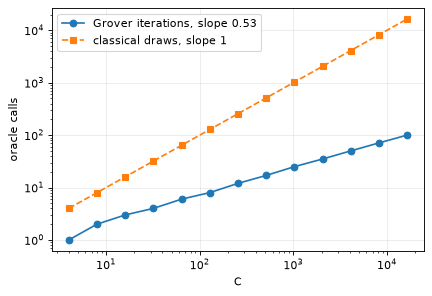

[C6] amplitude amplification finds one of the top-1/C points with O(sqrt(C)) calls
      paper: exponent 1/2 in C | this notebook: fitted exponent 0.53, success >= 0.95 -> REPRODUCED


In [19]:
for q in (3, 4, 5, 6):
    for CC in (2, 4, 8):
        if 2 ** q // CC < 1: continue
        Mq = 2 ** q // CC; sg = np.ones(2 ** q); sg[:Mq] = -1
        o = QuantumCircuit(q); o.append(DiagonalGate(list(sg)), range(q))
        Qq = grover_operator(o); th = math.asin(math.sqrt(Mq / 2 ** q))
        for r in (1, 2, 3):
            qcg = QuantumCircuit(q); qcg.h(range(q))
            for _ in range(r): qcg.compose(Qq, inplace=True)
            assert abs(Statevector(qcg).probabilities()[:Mq].sum() - math.sin((2 * r + 1) * th) ** 2) < 1e-9
print("[assertion passed] Grover success probability sin^2((2r+1) theta) == executed circuit (q = 3..6, C = 2, 4, 8, r = 1..3)")
Cs = [2 ** k for k in range(2, 15)]
r_star = [int(math.floor(math.pi / (4 * math.asin(math.sqrt(1 / C))))) for C in Cs]
s_amp = loglog_slope(Cs, r_star)
p_end = [math.sin((2 * r + 1) * math.asin(math.sqrt(1 / C))) ** 2 for r, C in zip(r_star, Cs)]
print(f"optimal Grover iterations r*(C) for C = 4 ... 16384 grows as C^{s_amp:.2f} (claim 1/2); classical expected draws = C^1; min success probability {min(p_end):.3f}")
fig, ax = plt.subplots(figsize=(5.5, 3.8)); ax.loglog(Cs, r_star, "o-", label=f"Grover iterations, slope {s_amp:.2f}"); ax.loglog(Cs, Cs, "s--", label="classical draws, slope 1")
ax.set_xlabel("C"); ax.set_ylabel("oracle calls"); ax.legend(); plt.tight_layout(); plt.show()
claim("C6", "amplitude amplification finds one of the top-1/C points with O(sqrt(C)) calls", "exponent 1/2 in C", f"fitted exponent {s_amp:.2f}, success >= {min(p_end):.2f}", within(s_amp, 0.5))

### 4.5 Appendix C: cost of the sampling strategies (Table I)

* **Classical threshold strategy:** estimating the $(1-1/C)$ quantile to relative precision $\epsilon'=\epsilon/C$ with probability $1-e^{-\beta}$ needs
  $n\ge 2\frac{1-p_C}{p_C}\epsilon'^{-2}\,[\mathrm{erf}^{-1}(1-e^{-\beta})]^2$ samples (eq. C17), i.e. $O(\epsilon^{-2}\beta C)$. First a Monte Carlo check of that formula on the
  real informativeness values, then the scaling.
* **Quantum threshold strategy:** the same quantile is found with amplitude estimation; the cost is read from the paper's theorem 6 (smallest $J$ with error bound
  $\le\epsilon'p_C$), repeated $R$ times with the median lemma so that the failure probability is $\le e^{-\beta}$. The paper states $O(\epsilon^{-1}\beta C)$.
* **Classical greedy with a noisy score:** the paper argues $\Omega(\beta^2C)$ (eqs. C6-C11). The comparison probability and its $\sqrt2$ are checked by Monte Carlo.

In [20]:
# (a) Monte Carlo check of the classical sample size of eq. (C17)
pC_ = lambda C: 1 - 1 / C
def n_classical(eps, C, beta):
    epsp = eps / C
    return 2 * (1 - pC_(C)) / pC_(C) / epsp ** 2 * special.erfinv(1 - math.exp(-beta)) ** 2
rmc = np.random.default_rng(SEED + 8); rows = []
for C, eps, beta in [(10, 0.5, 2.0), (10, 0.25, 2.0), (20, 0.5, 3.0), (20, 0.25, 1.0)]:
    n = int(math.ceil(n_classical(eps, C, beta))); thr = np.quantile(score_pool, pC_(C)); epsp = eps / C
    draws = rmc.integers(0, len(Xp), (MC_TRIALS, n)); Kc = (score_pool[draws] <= thr).sum(1)
    ok = float(np.mean(np.abs(Kc - n * pC_(C)) <= epsp * pC_(C) * n)); rows.append((C, eps, beta, n, ok, 1 - math.exp(-beta)))
chk = pd.DataFrame(rows, columns=["C", "eps", "beta", "n (eq. C17)", "measured success", "claimed >= 1-exp(-beta)"]); print(chk.round(3).to_string(index=False))

# (b) scaling of the classical and quantum cost
def J_bound(a, delta):
    s = math.sqrt(a * (1 - a)); t = (-2 * np.pi * s + math.sqrt(4 * np.pi ** 2 * s ** 2 + 4 * np.pi ** 2 * delta)) / (2 * np.pi ** 2); return 1 / t
d6 = 1 - 8 / np.pi ** 2
def R_median(beta): return int(math.ceil(beta / -math.log(2 * math.sqrt(d6 * (1 - d6)))))
def cost_quantum(eps, C, beta):
    a = 1 / C; delta = (eps / C) * pC_(C)
    return R_median(beta) * (2 * J_bound(a, delta) + 1)
def cost_classical(eps, C, beta): return n_classical(eps, C, beta)
epsg = [0.4 * 2 ** (-k) for k in range(0, 7)]; Cg = [4, 8, 16, 32, 64, 128, 256]; bg = [1, 2, 4, 8, 16, 32]
fits = {}
for nm, fn in [("classical threshold", cost_classical), ("quantum threshold (QAE)", cost_quantum)]:
    se = loglog_slope(epsg, [fn(e, 16, 3.0) for e in epsg]); sc = loglog_slope(Cg, [fn(0.1, C, 3.0) for C in Cg]); sb = loglog_slope(bg[2:], [fn(0.1, 16, b) for b in bg[2:]])
    fits[nm] = (se, sc, sb)
fit_df = pd.DataFrame(fits, index=["exponent in eps", "exponent in C", "exponent in beta"]).T
paper_df = pd.DataFrame({"exponent in eps": [-2, -1], "exponent in C": [1, 1], "exponent in beta": [1, 1]}, index=["classical threshold (paper)", "quantum threshold (paper)"])
print(fit_df.round(2).to_string()); print("paper, Table I:"); print(paper_df.to_string())
# exact QAE distribution cross-check of the quantum cost at one setting
a_ = 1 / 16; dlt = (0.1 / 16) * pC_(16)
for M in range(2, 16):
    at = np.sin(np.pi * np.arange(2 ** M) / 2 ** M) ** 2
    if qae_dist(a_, M)[np.abs(at - a_) <= dlt].sum() >= 8 / np.pi ** 2: break
print(f"exact QAE distribution at C=16, eps=0.1: smallest M with success >= 8/pi^2 is M={M} -> J={2**M}; bound-based J = {J_bound(a_, dlt):.0f}")
claim("C7a", "eq. C17: sample size for the classical threshold gives probability >= 1 - exp(-beta)", "formula", f"measured {chk['measured success'].min():.2f}..{chk['measured success'].max():.2f}",
      "reproduced" if (chk["measured success"] >= chk["claimed >= 1-exp(-beta)"] - 0.02).all() else "not reached",
      "the formula rests on a normal approximation of a binomial count; for beta = 1 the discrete window falls short")
claim("C7b", "classical threshold strategy costs O(eps^-2 beta C)", "(-2, 1, 1)", "(%.2f, %.2f, %.2f)" % fits["classical threshold"],
      "reproduced" if abs(fits["classical threshold"][0] + 2) <= 0.15 and abs(fits["classical threshold"][1] - 1) <= 0.15 and abs(fits["classical threshold"][2] - 1) <= 0.25 else "not reached")
qf = fits["quantum threshold (QAE)"]
claim("C7c", "quantum threshold strategy costs O(eps^-1 beta C)", "(-1, 1, 1)", "(%.2f, %.2f, %.2f)" % qf,
      "reproduced" if abs(qf[0] + 1) <= 0.15 and qf[1] <= 1.15 and abs(qf[2] - 1) <= 0.25 else "not reached",
      f"eps and beta match; the C exponent {qf[1]:.2f} is below the stated 1, i.e. the stated bound holds but is loose")

 C  eps  beta  n (eq. C17)  measured success  claimed >= 1-exp(-beta)
10 0.50   2.0          100             0.866                    0.865
10 0.25   2.0          397             0.868                    0.865
20 0.50   3.0          325             0.945                    0.950
20 0.25   1.0          274             0.603                    0.632
                         exponent in eps  exponent in C  exponent in beta
classical threshold                -2.00           0.94              1.14
quantum threshold (QAE)            -0.98           0.47              0.99
paper, Table I:
                             exponent in eps  exponent in C  exponent in beta
classical threshold (paper)               -2              1                 1
quantum threshold (paper)                 -1              1                 1
exact QAE distribution at C=16, eps=0.1: smallest M with success >= 8/pi^2 is M=6 -> J=64; bound-based J = 266
[C7a] eq. C17: sample size for the classical threshold gives probab

P(mean0 > mean1): Monte Carlo 0.8363 | eq. (C6) as printed 0.9171 | with the missing sqrt(2) 0.8364
local exponent d log(c*m) / d log(beta): [1.77 1.79 1.85 1.9  1.94 1.96 1.98 1.99 1.99 2.   2.   2.   2.  ]


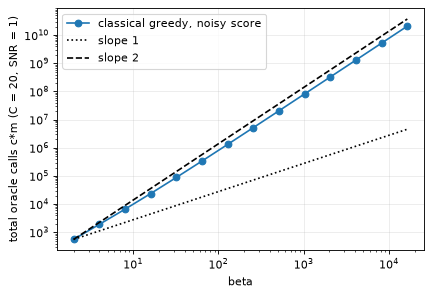

[C8a] eq. (C6): P(mean0 > mean1) = 1/2 + erf(.)/2 with argument (mu0-mu1)/sqrt(s^2/m0 + s^2/m1)
      paper: formula | this notebook: Monte Carlo 0.836 vs printed 0.917 -> NOT REACHED  (the printed argument misses a factor sqrt(2); the scaling argument is unaffected)
[C8b] classical greedy with a noisy score needs Omega(beta^2 C) oracle calls
      paper: exponent 2 in beta | this notebook: local exponent 2.00 for beta = 2^11..2^14 (analytic evaluation, increases towards 2 with beta) -> REPRODUCED


In [21]:
# (c) noisy score, classical greedy: Monte Carlo check of the normal-difference formula (C6) and the beta-dependence of the total cost c*m
rmc = np.random.default_rng(SEED + 9); sigma, delta_mu, m_ev = 1.0, 0.4, 12
mu0 = rmc.normal(delta_mu, sigma / math.sqrt(m_ev), 200000); mu1 = rmc.normal(0, sigma / math.sqrt(m_ev), 200000)
p_mc = float(np.mean(mu0 > mu1))
p_paper = 0.5 + 0.5 * special.erf(delta_mu / math.sqrt(sigma ** 2 / m_ev + sigma ** 2 / m_ev))                      # eq. (C6) as printed
p_true = 0.5 + 0.5 * special.erf(delta_mu / math.sqrt(2 * (sigma ** 2 / m_ev + sigma ** 2 / m_ev)))                  # normal CDF of the difference
print(f"P(mean0 > mean1): Monte Carlo {p_mc:.4f} | eq. (C6) as printed {p_paper:.4f} | with the missing sqrt(2) {p_true:.4f}")

def z_sq(L):
    """erfcinv(2 p)^2 for p = exp(-L), stable for large L."""
    if L < 30: return float(special.erfcinv(2 * math.exp(-L)) ** 2)
    z2 = L
    for _ in range(6): z2 = L - math.log(2) - 0.5 * math.log(np.pi * z2)
    return z2
def total_calls_greedy(beta, C, snr2=1.0):
    c = beta / -math.log(1 - 1 / C)                                  # candidates (eq. 34)
    pprime = -math.expm1(math.log1p(-math.exp(-beta)) / c)           # per-comparison error 1-(1-e^-beta)^(1/c)
    L = -math.log(pprime) if pprime > 0 else beta + math.log(c)
    m = 4.0 / snr2 * z_sq(L)                                         # evaluations per candidate (correct normal CDF); the paper's (C11) has 2 instead of 4
    return c * m
betas = np.array([2 ** k for k in range(1, 15)], float)
T = np.array([total_calls_greedy(b, 20) for b in betas]); local = np.diff(np.log2(T)) / np.diff(np.log2(betas))
print("local exponent d log(c*m) / d log(beta):", np.round(local, 2))
s_beta = float(local[-4:].mean())
fig, ax = plt.subplots(figsize=(5.5, 3.8)); ax.loglog(betas, T, "o-", label="classical greedy, noisy score"); ax.loglog(betas, betas * T[0] / betas[0], "k:", label="slope 1"); ax.loglog(betas, betas ** 2 * T[0] / betas[0] ** 2, "k--", label="slope 2")
ax.set_xlabel("beta"); ax.set_ylabel("total oracle calls c*m (C = 20, SNR = 1)"); ax.legend(); plt.tight_layout(); plt.show()
claim("C8a", "eq. (C6): P(mean0 > mean1) = 1/2 + erf(.)/2 with argument (mu0-mu1)/sqrt(s^2/m0 + s^2/m1)", "formula", f"Monte Carlo {p_mc:.3f} vs printed {p_paper:.3f}",
      "reproduced" if abs(p_mc - p_paper) <= 0.02 else "not reached", "the printed argument misses a factor sqrt(2); the scaling argument is unaffected")
claim("C8b", "classical greedy with a noisy score needs Omega(beta^2 C) oracle calls", "exponent 2 in beta", f"local exponent {s_beta:.2f} for beta = 2^11..2^14 (analytic evaluation, increases towards 2 with beta)", within(s_beta, 2.0))

### 4.6 The low-rank approximation of the quantum SVM (Sec. IV B): error $O(n^{-1/2})$ with $\kappa_{\rm eff}=O(1)$

The quantum SVM keeps only the eigenvalues $\lambda\ge\kappa_{\rm eff}^{-1}$ of $\hat F=F/\mathrm{tr}F$. The paper (quoting Rebentrost et al.) says the kernel
matrix has $O(1)$ eigenvalues of size $O(1)$ and $O(n)$ eigenvalues of size $O(1/n)$, so that the filtered solution differs from the exact one by $O(n^{-1/2})$.
This is checked on the real MNIST Gram matrix: the distance between the normalised exact and filtered solution states $|b,\alpha\rangle$ as a function of $n$.

 kappa_eff    n  state_error  eigenvalues_kept
      10.0   25       1.4139                 1
      10.0   50       1.4138                 1
      10.0  100       1.4141                 1
      10.0  200       1.4141                 1
      10.0  400       1.4142                 1
      10.0  800       1.4142                 1
      10.0 1600       1.4142                 1
      10.0 3000       1.4142                 1
     100.0   25       1.3718                16
     100.0   50       1.3262                15
     100.0  100       1.3767                13
     100.0  200       1.4048                14
     100.0  400       1.4112                12
     100.0  800       1.4132                12
     100.0 1600       1.4138                12
     100.0 3000       1.4140                12
   10000.0   25       1.3285                25
   10000.0   50       1.0152                50
   10000.0  100       0.4366               100
   10000.0  200       0.5101               189
   10000.0  4

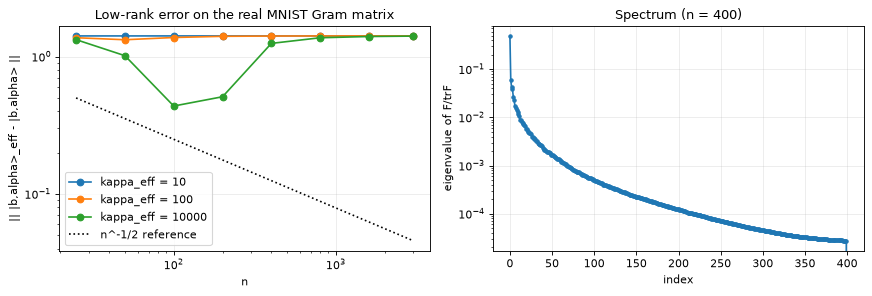

fitted exponents (kappa_eff = O(1) values): {10.0: 0.0, 100.0: 0.01} | kappa_eff = 1e4 errors: [1.328, 1.015, 0.437, 0.51, 1.248, 1.371, 1.4, 1.41]
[C9] low-rank filtering with kappa_eff = O(1) induces an error O(n^-1/2)
      paper: exponent <= -1/2 | this notebook: exponents 0.00 (kappa 10), 0.01 (kappa 100); error at largest n [1.41, 1.41] -> NOT REACHED  (the assumed spectrum (O(1) eigenvalues of O(1), the rest O(1/n)) is not what real pixel data show)


In [22]:
def lowrank_error(n, kappa, seed=0):
    ids = np.random.default_rng(seed).choice(len(Xp), n, replace=False); X, y = Xp[ids], yp[ids]
    F = np.zeros((n + 1, n + 1)); F[0, 1:] = 1; F[1:, 0] = 1; F[1:, 1:] = X @ X.T + REG * np.eye(n)
    lam, V = np.linalg.eigh(F / np.trace(F)); rhs = np.r_[0.0, y]; coef = V.T @ rhs
    x_ex = V @ (coef / lam); keep = lam >= 1 / kappa
    x_ef = V[:, keep] @ (coef[keep] / lam[keep])
    x_ex, x_ef = x_ex / np.linalg.norm(x_ex), x_ef / np.linalg.norm(x_ef)
    return float(min(np.linalg.norm(x_ex - x_ef), np.linalg.norm(x_ex + x_ef))), int(keep.sum()), lam
lr_rows = []
KAPPAS = (10.0, 100.0, 10000.0)
for kappa in KAPPAS:
    for n in LOWRANK_NS:
        n = min(n, len(Xp)); e, kept, lam = lowrank_error(n, kappa); lr_rows.append((kappa, n, e, kept))
lr = pd.DataFrame(lr_rows, columns=["kappa_eff", "n", "state_error", "eigenvalues_kept"]); print(lr.round(4).to_string(index=False))
_, _, lam_ex = lowrank_error(min(400, len(Xp)), 10.0)
big_lam = int((lam_ex > 0.05).sum()); print(f"\nspectrum of F/trF at n = 400: {big_lam} eigenvalues > 0.05, largest {lam_ex.max():.3f}, median {np.median(lam_ex):.2e}, smallest {lam_ex.min():.2e}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for kappa in KAPPAS:
    d = lr[lr.kappa_eff == kappa]; ax[0].loglog(d.n, d.state_error, "o-", label=f"kappa_eff = {kappa:g}")
ax[0].loglog(LOWRANK_NS, 0.5 * np.array(LOWRANK_NS, float) ** -0.5 / LOWRANK_NS[0] ** -0.5, "k:", label="n^-1/2 reference")
ax[0].set_xlabel("n"); ax[0].set_ylabel("|| |b,alpha>_eff - |b,alpha> ||"); ax[0].legend(); ax[0].set_title("Low-rank error on the real MNIST Gram matrix")
ax[1].semilogy(np.sort(lam_ex)[::-1], ".-"); ax[1].set_xlabel("index"); ax[1].set_ylabel("eigenvalue of F/trF"); ax[1].set_title("Spectrum (n = 400)")
plt.tight_layout(); plt.show()
sl = {k: loglog_slope(lr[lr.kappa_eff == k].n, np.maximum(lr[lr.kappa_eff == k].state_error, 1e-12)) for k in KAPPAS[:2]}
print("fitted exponents (kappa_eff = O(1) values):", {k: round(v, 2) for k, v in sl.items()}, "| kappa_eff = 1e4 errors:", lr[lr.kappa_eff == KAPPAS[2]].state_error.round(3).tolist())
claim("C9", "low-rank filtering with kappa_eff = O(1) induces an error O(n^-1/2)", "exponent <= -1/2", f"exponents {sl[10.0]:.2f} (kappa 10), {sl[100.0]:.2f} (kappa 100); error at largest n {lr[(lr.n == lr.n.max()) & (lr.kappa_eff < 1000)].state_error.round(2).tolist()}",
      "reproduced" if min(sl.values()) <= -0.5 + 0.15 else "not reached", "the assumed spectrum (O(1) eigenvalues of O(1), the rest O(1/n)) is not what real pixel data show")

### 4.7 What cannot be tested: the polylogarithmic quantum cost, and what can: loader cost and classical cost

The headline claim (cost polylogarithmic in $n$ and $m$, an exponential speed-up over classical, reduced to polynomial by dequantisation) assumes a qRAM, HHL-type
linear algebra and fault-tolerant hardware. None of that exists here. Two things around it *are* measurable: (i) the gate cost of loading the states **without** a
qRAM, using the generic loader of this notebook; (ii) the classical wall-clock cost of one informativeness evaluation as a function of $n$ and $m$.

 qubits  amplitudes  CX  depth
      2           4   1      3
      3           8   4      9
      4          16  11     23
      5          32  26     53
      6          64  57    115
      7         128 120    241
      8         256 247    495



classical time of one round (LS-SVM solve + informativeness of 200 candidates): exponent in n 1.75 (m = 784), exponent in m 0.51 (n = 100)


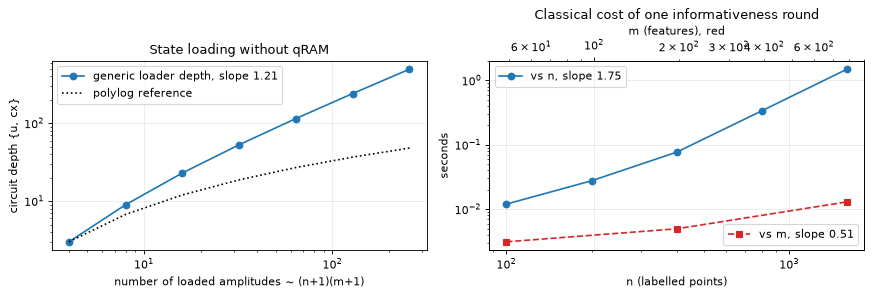

[C10] quantum cost is polylogarithmic in n and m (exponential speed-up, needs qRAM)
      paper: polylog(n m) | this notebook: generic loader depth grows as (n m)^1.21; the qRAM and HHL parts are not simulated -> CANNOT BE CHECKED  (the paper itself names the qRAM as an assumption that 'hides the cost')
[C11] the classical algorithm is polynomial in n and m
      paper: polynomial | this notebook: measured exponents n^1.75, m^0.51 -> REPRODUCED  (polynomial (not polylogarithmic) growth: exponent > 1 in n (Gram matrix, inversion) and > 1/4 in m (Gram matrix, w.x products; timings are noisy))


In [23]:
sp_rows = []
for q in SP_QUBITS:
    v = np.random.default_rng(q).normal(size=2 ** q); v /= np.linalg.norm(v)
    qc_ = QuantumCircuit(q); qc_.append(StatePreparation(v), range(q))
    t_ = transpile(qc_, basis_gates=["u", "cx"], optimization_level=0); sp_rows.append((q, 2 ** q, t_.count_ops().get("cx", 0), t_.depth()))
sp = pd.DataFrame(sp_rows, columns=["qubits", "amplitudes", "CX", "depth"]); print(sp.to_string(index=False))
s_sp = loglog_slope(sp.amplitudes, sp.depth)

def downsample(X, m):
    side = int(round(math.sqrt(m))); k = 28 // side
    return X.reshape(len(X), 28, 28)[:, :side * k, :side * k].reshape(len(X), side, k, side, k).mean((2, 4)).reshape(len(X), -1)
def cost_eval(n, m, reps=3):
    Xs = downsample(Xp, m)[: n + 200] if m != 784 else Xp[: n + 200]
    if len(Xs) < n + 200: Xs = np.vstack([Xs] * (1 + (n + 200) // len(Xs)))[: n + 200]
    ys = np.where(np.arange(n) % 2 == 0, 1.0, -1.0); best = 1e9
    for _ in range(reps):
        t0 = time.perf_counter(); Fi, bb, aa = lssvm_fit(Xs[:n], ys, REG); informativeness(Fi, bb, aa, Xs[:n], ys, Xs[n:n + 200]); best = min(best, time.perf_counter() - t0)
    return best
N_FOR_M = TIME_NS[0]                      # small n so that the n*m terms (not the n^3 inversion) dominate the sweep over m
tn = [cost_eval(n, 784) for n in TIME_NS]; tm = [cost_eval(N_FOR_M, m) for m in TIME_MS]
s_n, s_m = loglog_slope(TIME_NS, tn), loglog_slope(TIME_MS, tm)
print(f"\nclassical time of one round (LS-SVM solve + informativeness of 200 candidates): exponent in n {s_n:.2f} (m = 784), exponent in m {s_m:.2f} (n = {N_FOR_M})")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(sp.amplitudes, sp.depth, "o-", label=f"generic loader depth, slope {s_sp:.2f}"); ax[0].loglog(sp.amplitudes, np.log2(sp.amplitudes) ** 2 * sp.depth.iloc[0] / np.log2(sp.amplitudes.iloc[0]) ** 2, "k:", label="polylog reference")
ax[0].set_xlabel("number of loaded amplitudes ~ (n+1)(m+1)"); ax[0].set_ylabel("circuit depth {u, cx}"); ax[0].legend(); ax[0].set_title("State loading without qRAM")
ax[1].loglog(TIME_NS, tn, "o-", label=f"vs n, slope {s_n:.2f}"); ax[1].set_xlabel("n (labelled points)"); ax[1].set_ylabel("seconds"); ax2 = ax[1].twiny(); ax2.loglog(TIME_MS, tm, "s--", c="tab:red", label=f"vs m, slope {s_m:.2f}"); ax2.set_xlabel("m (features), red"); ax[1].legend(loc="upper left"); ax2.legend(loc="lower right")
ax[1].set_title("Classical cost of one informativeness round")
plt.tight_layout(); plt.show()
claim("C10", "quantum cost is polylogarithmic in n and m (exponential speed-up, needs qRAM)", "polylog(n m)", f"generic loader depth grows as (n m)^{s_sp:.2f}; the qRAM and HHL parts are not simulated", "cannot be checked",
      "the paper itself names the qRAM as an assumption that 'hides the cost'")
claim("C11", "the classical algorithm is polynomial in n and m", "polynomial", f"measured exponents n^{s_n:.2f}, m^{s_m:.2f}", "reproduced" if s_n > 1.0 and s_m > 0.25 else "not reached", "polynomial (not polylogarithmic) growth: exponent > 1 in n (Gram matrix, inversion) and > 1/4 in m (Gram matrix, w.x products; timings are noisy)")

## 5. Active learning of the class distance against real attacks

**Set-up (pool-based).** The learner starts with 10 labelled images (5 per digit). In each round it asks for the label of one more image from the
unlabelled pool, with one of five rules; the labels are revealed from the real ground truth. After every 10 labels, and at a few checkpoints for the heavier attacks, it is scored on the
held-out real test images.

| Rule | Description |
|---|---|
| `random` | uniform random query (the passive baseline) |
| `uncertainty` | classical active learning: the pool image closest to the hyperplane (smallest abs. f) |
| `informativeness (Alg. 1)` | **the paper**: draw $c=\lceil\beta/(-\ln(1-1/C))\rceil$ candidates uniformly, keep the one with the largest *expected* informativeness $P_+|w^+|+P_-|w^-|$ |
| `informativeness (predicted class)` | same draws, score $P_c|w_{n+1}|$ with the predicted class only (ablation of the single-class reading of eq. 2) |
| `informativeness (exhaustive)` | classical argmax over the whole pool (what Algorithm 1 approximates, at pool-size cost) |

**What is measured.** The paper's goal is to learn the minimum class distance $r_p$ (and so the margin $1/|w|$ of the perfect SVM). Two proxies are tracked: the ratio
$|w|/|w^*|$ of the current weight norm to that of the SVM trained on *all* pool labels, and the ratio $\hat r_p/r_p^*$ of the smallest distance between opposite-class
labelled images to the smallest distance between opposite-class pool images (always $\ge1$; the paper warns that over-estimating $r_p$ voids the theorem).
Robustness is measured with **real attacks**: exact / PGD $L_2$ attacks on the linear LS-SVM, $L_2$ PGD on an RBF-SVM trained on the same labels, and for 1-nearest-neighbour (the
classifier assumed by the KH theorem) the triangle-inequality certified radius plus an explicit bisector attack. The theorem's own condition, that the labelled set is a
$\delta$-cover with $\delta<r_p-\epsilon$, is evaluated as well.

In [24]:
# ---------------- reference quantities from the full pool (the learner never sees them)
from scipy.spatial.distance import cdist
Finv_star, b_star, al_star = lssvm_fit(Xp, yp); w_star = al_star @ Xp
Dpp = cdist(Xp[yp > 0], Xp[yp < 0]); R_P_STAR = float(Dpp.min()); del Dpp
print(f"SVM on all {len(Xp)} pool labels: |w*| = {np.linalg.norm(w_star):.3f} (margin 1/|w*| = {1/np.linalg.norm(w_star):.3f}); test accuracy {np.mean(np.sign(Xt @ w_star + b_star) == yt):.3f}")
print(f"smallest distance between opposite-class pool images r_p* = {R_P_STAR:.3f}  (typical image norm {np.linalg.norm(Xp, axis=1).mean():.2f})")

def lin_metrics(w, b, X, y):
    f = X @ w + b; ok = np.sign(f) == y; dist = np.abs(f) / np.linalg.norm(w)     # exact L2 distance to the hyperplane = minimal attack size
    return float(ok.mean()), np.array([float(np.mean(ok & (dist > e))) for e in EPS_GRID])

def pgd_l2(grad_fn, X, y, eps, steps=PGD_STEPS, clip=True):
    """Projected gradient descent on the margin y*f (L2 ball of radius eps)."""
    Xa = X.copy(); step = 2.5 * eps / steps
    for _ in range(steps):
        g = -y[:, None] * grad_fn(Xa)
        Xa = Xa + step * g / (np.linalg.norm(g, axis=1, keepdims=True) + 1e-12)
        d = Xa - X; Xa = X + d * np.minimum(1.0, eps / (np.linalg.norm(d, axis=1, keepdims=True) + 1e-12))
        if clip: Xa = np.clip(Xa, 0, 1)
    return Xa

# ---- assertion: PGD on the linear model reaches the exact analytic robust accuracy
Fi_t, b_t, al_t = lssvm_fit(Xp[lab0], yp[lab0]); w_t = al_t @ Xp[lab0]
for e in (0.5, 1.0, 2.0):
    Xa = pgd_l2(lambda Z: np.tile(w_t, (len(Z), 1)), Xt, yt, e, clip=False)
    acc_pgd = float(np.mean(np.sign(Xa @ w_t + b_t) == yt)); acc_exact = lin_metrics(w_t, b_t, Xt, yt)[1][EPS_GRID.index(e)] if e in EPS_GRID else float(np.mean((np.sign(Xt @ w_t + b_t) == yt) & (np.abs(Xt @ w_t + b_t) / np.linalg.norm(w_t) > e)))
    assert abs(acc_pgd - acc_exact) < 0.01, (e, acc_pgd, acc_exact)
print("[assertion passed] L2 PGD on the linear LS-SVM == exact analytic robust accuracy (eps = 0.5, 1, 2)")

def rbf_fit(X, y):
    gam = 1.0 / (X.shape[1] * X.var()); clf = SVC(kernel="rbf", C=10.0, gamma=gam).fit(X, y); return clf, gam
def rbf_grad(clf, gam):
    sv, dc = clf.support_vectors_, clf.dual_coef_[0]; sv2 = (sv ** 2).sum(1)
    def g(X):
        k = np.exp(-gam * ((X ** 2).sum(1)[:, None] + sv2[None] - 2 * X @ sv.T)) * dc[None]
        return -2 * gam * (X * k.sum(1, keepdims=True) - k @ sv)
    return g

def nn_metrics(XL, yL, X, y, eps_max=EPS_HEAVY[-1]):
    """1-NN: triangle-inequality certified radius and an explicit bisector attack (upper bound on the robust radius)."""
    D = cdist(X, XL); same = yL[None, :] == y[:, None]
    ds = np.where(same, D, np.inf); do = np.where(~same, D, np.inf); js = ds.argmin(1)
    ok = ds.min(1) < do.min(1); cert = np.where(ok, (do.min(1) - ds.min(1)) / 2, 0.0)
    att = np.full(len(X), np.inf)
    for i in np.where(ok)[0]:
        s = XL[js[i]]
        for z_i in np.where(~same[i])[0]:
            z = XL[z_i]; dz = np.linalg.norm(z - s)
            t = (D[i, z_i] ** 2 - ds[i, js[i]] ** 2) / (2 * dz)
            if t > eps_max or t >= att[i]: continue
            xa = X[i] + (t + 1e-6) * (z - s) / dz
            if yL[np.argmin(((XL - xa) ** 2).sum(1))] != y[i]: att[i] = t
    acc = float(ok.mean())
    return acc, np.array([float(np.mean(ok & (cert > e))) for e in EPS_HEAVY]), np.array([float(np.mean(ok & (att > e))) for e in EPS_HEAVY])

def cover_radius(XL, yL, X, y):
    """delta of the labelled set as a cover of the real pool images (per class, max distance to the nearest labelled image of the same class)."""
    d = [cdist(X[y == c], XL[yL == c]).min(1).max() for c in (-1.0, 1.0)]
    return float(max(d))
print("helper functions ready")

SVM on all 3000 pool labels: |w*| = 3.537 (margin 1/|w*| = 0.283); test accuracy 0.954
smallest distance between opposite-class pool images r_p* = 3.678  (typical image norm 9.33)


[assertion passed] L2 PGD on the linear LS-SVM == exact analytic robust accuracy (eps = 0.5, 1, 2)
helper functions ready


In [25]:
METHODS = ["random", "uncertainty", "informativeness (Alg. 1)", "informativeness (predicted class)", "informativeness (exhaustive)"]
N_CAND = int(math.ceil(BETA / -math.log(1 - 1 / C_QUANT)))
CHECKPOINTS = [40, BUDGET] if FAST_MODE else [20, 50, 100, BUDGET]
atk_idx = np.random.default_rng(SEED).choice(len(Xt), min(N_ATK, len(Xt)), replace=False)
print(f"Algorithm 1 draws c = {N_CAND} candidates per query (beta={BETA:g}, C={C_QUANT}); budget {BUDGET} labels; checkpoints {CHECKPOINTS}; seeds {N_SEEDS}")

def run_al(method, seed):
    ri = np.random.default_rng(seed); rm = np.random.default_rng(seed + 1000)
    lab = list(ri.permutation(np.where(yp > 0)[0])[:N0 // 2]) + list(ri.permutation(np.where(yp < 0)[0])[:N0 // 2])
    unl = np.ones(len(Xp), bool); unl[lab] = False
    log, snaps = [], {}
    while True:
        Xl, yl = Xp[lab], yp[lab]; Finv, b, al = lssvm_fit(Xl, yl); w = al @ Xl
        n = len(lab)
        if n % 10 == 0 or n in CHECKPOINTS:
            acc, rob = lin_metrics(w, b, Xt, yt)
            dmin = cdist(Xl[yl > 0], Xl[yl < 0]).min()
            log.append(dict(method=method, seed=seed, n=n, acc=acc, rob_ref=rob[EPS_GRID.index(EPS_REF)], rob_auc=rob.mean(), wratio=np.linalg.norm(w) / np.linalg.norm(w_star),
                            rp_ratio=dmin / R_P_STAR, delta=cover_radius(Xl, yl, Xp, yp), mean_norm_labelled=np.linalg.norm(Xl[N0:], axis=1).mean() if n > N0 else np.nan, rob=rob))
        if n in CHECKPOINTS: snaps[n] = (np.array(lab), w.copy(), b)
        if n >= BUDGET: break
        U = np.where(unl)[0]
        if method == "random": j = rm.choice(U)
        elif method == "uncertainty": j = U[np.argmin(np.abs(Xp[U] @ w + b))]
        elif method in ("informativeness (Alg. 1)", "informativeness (predicted class)"):
            Cd = rm.choice(U, min(N_CAND, len(U)), replace=False)
            sc = informativeness(Finv, b, al, Xl, yl, Xp[Cd]); j = Cd[np.argmax(sc[0] if method.endswith("(Alg. 1)") else sc[1])]
        else:
            j = U[np.argmax(informativeness(Finv, b, al, Xl, yl, Xp[U])[0])]
        lab.append(j); unl[j] = False
    return log, snaps

t0 = time.time(); LOGS, SNAPS = [], {}
for method in METHODS:
    for s in range(N_SEEDS):
        lg, sn = run_al(method, SEED + s); LOGS += lg; SNAPS[(method, SEED + s)] = sn
    print(f"{method:38s} done ({time.time() - t0:.0f}s)")
AL = pd.DataFrame(LOGS)
print(AL[AL.n == BUDGET].groupby("method")[["acc", "rob_ref", "rob_auc", "wratio", "rp_ratio", "delta"]].agg(["mean", "std"]).round(3).to_string())

Algorithm 1 draws c = 59 candidates per query (beta=3, C=20); budget 200 labels; checkpoints [20, 50, 100, 200]; seeds 5


random                                 done (23s)


uncertainty                            done (78s)


informativeness (Alg. 1)               done (114s)


informativeness (predicted class)      done (145s)


informativeness (exhaustive)           done (397s)
                                     acc        rob_ref        rob_auc        wratio        rp_ratio          delta       
                                    mean    std    mean    std    mean    std   mean    std     mean    std    mean    std
method                                                                                                                    
informativeness (Alg. 1)           0.828  0.045   0.006  0.003   0.114  0.012  0.677  0.027    1.259  0.022  11.268  0.192
informativeness (exhaustive)       0.773  0.078   0.049  0.077   0.141  0.031  0.545  0.190    1.329  0.330  11.461  0.157
informativeness (predicted class)  0.823  0.045   0.019  0.025   0.126  0.037  0.336  0.055    1.830  0.245  10.392  0.575
random                             0.893  0.014   0.002  0.001   0.105  0.003  0.677  0.017    1.410  0.055   9.890  0.252
uncertainty                        0.942  0.005   0.045  0.011   0.184  0.012  1.012  0.

In [26]:
# ---- heavier attacks at the checkpoints: RBF-SVM (L2 PGD) and 1-NN (certified radius + bisector attack)
HEAVY = []
for (method, seed), sn in SNAPS.items():
    for n, (lab, w, b) in sn.items():
        XL_, yL_ = Xp[lab], yp[lab]
        clf, gam = rbf_fit(XL_, yL_); gfun = rbf_grad(clf, gam)
        Xa_t, ya_t = Xt[atk_idx], yt[atk_idx]
        clean = float(np.mean(clf.predict(Xa_t) == ya_t))
        rob_rbf = []
        for e in EPS_HEAVY:
            Xa = pgd_l2(lambda Z: gfun(Z), Xa_t, ya_t, e, steps=PGD_STEPS_RBF)
            rob_rbf.append(float(np.mean((clf.predict(Xa) == ya_t) & (clf.predict(Xa_t) == ya_t))))
        acc_nn, cert, att = nn_metrics(XL_, yL_, Xa_t, ya_t)
        HEAVY.append(dict(method=method, seed=seed, n=n, rbf_clean=clean, rbf_rob=np.array(rob_rbf), nn_clean=acc_nn, nn_cert=cert, nn_att=att))
HV = pd.DataFrame(HEAVY)
HV["rbf_ref"] = [r[EPS_HEAVY.index(EPS_REF)] for r in HV.rbf_rob]; HV["nn_cert_ref"] = [r[EPS_HEAVY.index(EPS_REF)] for r in HV.nn_cert]; HV["nn_att_ref"] = [r[EPS_HEAVY.index(EPS_REF)] for r in HV.nn_att]
print(f"robust accuracy at eps = {EPS_REF} (mean over seeds), RBF-SVM under PGD and 1-NN certified / attacked:")
print(HV.groupby(["n", "method"])[["rbf_clean", "rbf_ref", "nn_clean", "nn_cert_ref", "nn_att_ref"]].mean().round(3).to_string())

robust accuracy at eps = 1.0 (mean over seeds), RBF-SVM under PGD and 1-NN certified / attacked:
                                       rbf_clean  rbf_ref  nn_clean  nn_cert_ref  nn_att_ref
n   method                                                                                  
20  informativeness (Alg. 1)               0.812    0.574     0.826        0.115       0.540
    informativeness (exhaustive)           0.802    0.554     0.791        0.173       0.518
    informativeness (predicted class)      0.742    0.534     0.777        0.252       0.534
    random                                 0.808    0.608     0.826        0.249       0.587
    uncertainty                            0.832    0.600     0.812        0.132       0.528
50  informativeness (Alg. 1)               0.867    0.625     0.848        0.115       0.587
    informativeness (exhaustive)           0.804    0.578     0.808        0.202       0.551
    informativeness (predicted class)      0.755    0.546     0.78

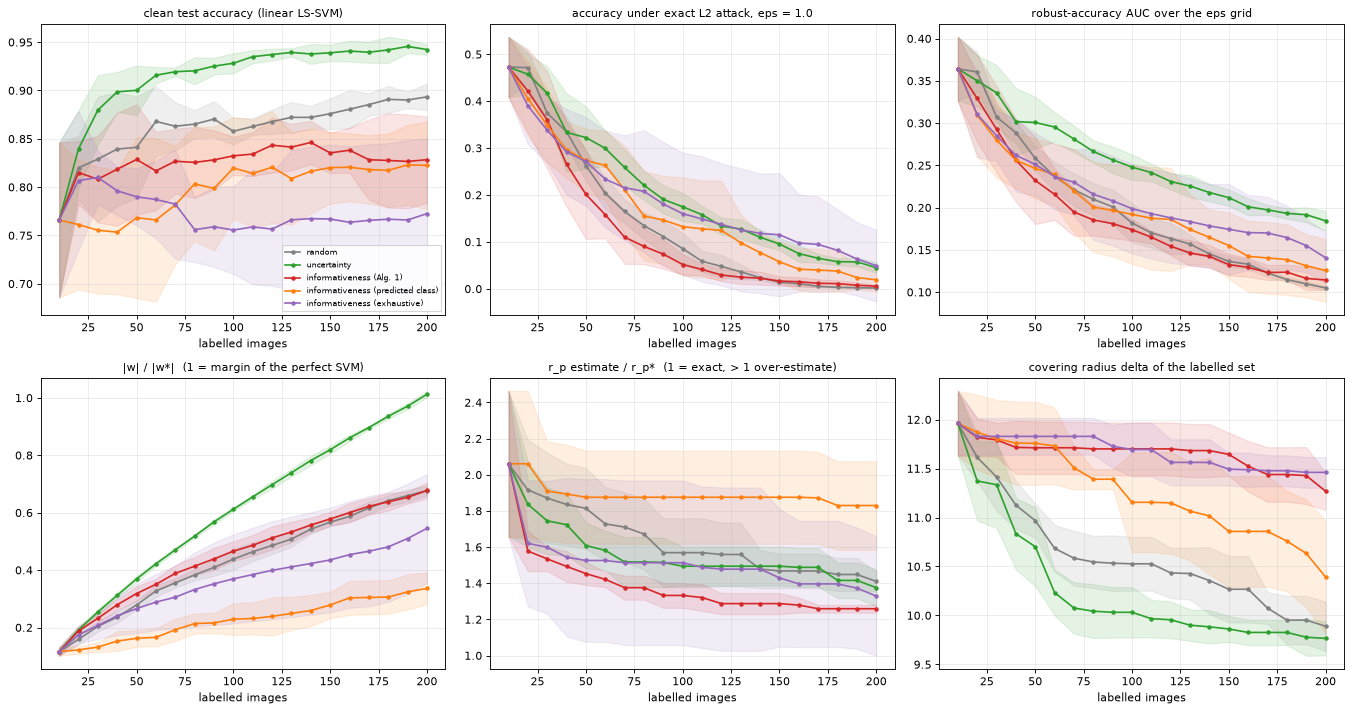

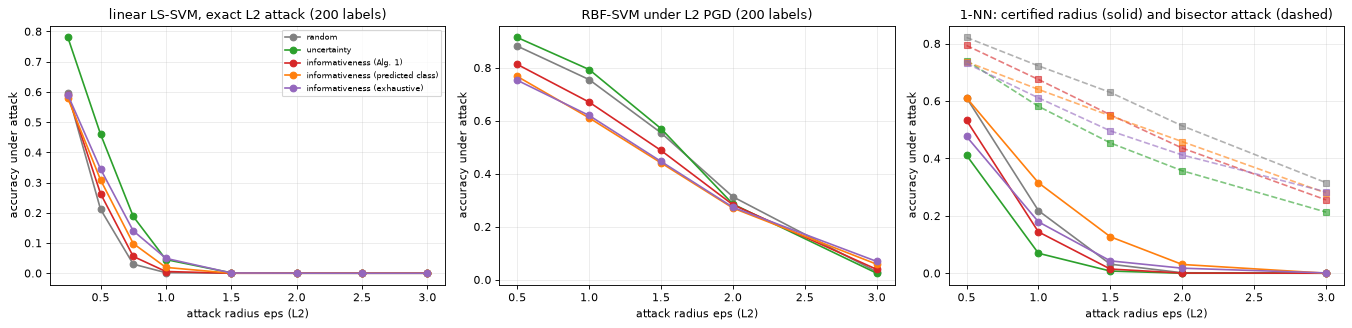

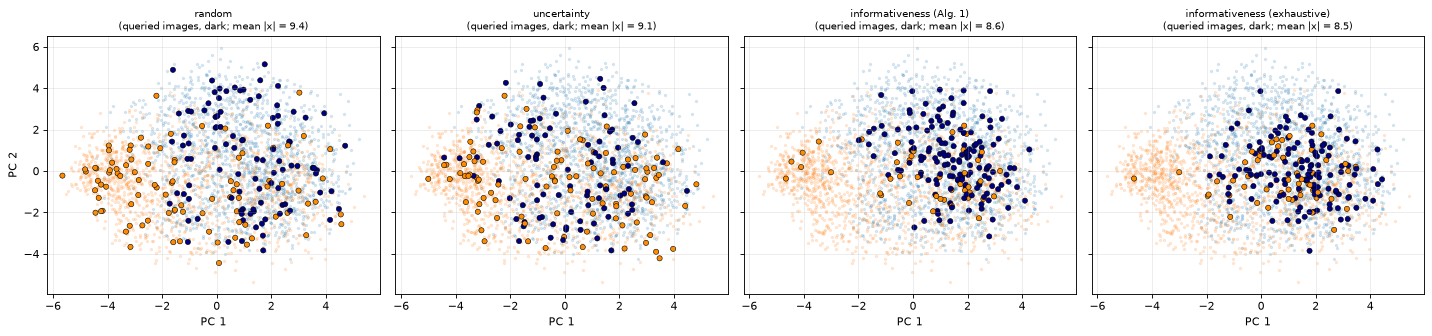

In [27]:
colors = {"random": "grey", "uncertainty": "tab:green", "informativeness (Alg. 1)": "tab:red", "informativeness (predicted class)": "tab:orange", "informativeness (exhaustive)": "tab:purple"}
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
panels = [("acc", "clean test accuracy (linear LS-SVM)"), ("rob_ref", f"accuracy under exact L2 attack, eps = {EPS_REF}"), ("rob_auc", "robust-accuracy AUC over the eps grid"),
          ("wratio", "|w| / |w*|  (1 = margin of the perfect SVM)"), ("rp_ratio", "r_p estimate / r_p*  (1 = exact, > 1 over-estimate)"), ("delta", "covering radius delta of the labelled set")]
for a, (col, ttl) in zip(ax.ravel(), panels):
    for m in METHODS:
        d = AL[AL.method == m].groupby("n")[col].agg(["mean", "std"]).dropna(); a.plot(d.index, d["mean"], "-o", ms=3, c=colors[m], label=m)
        a.fill_between(d.index, d["mean"] - d["std"], d["mean"] + d["std"], color=colors[m], alpha=0.12)
    a.set_title(ttl, fontsize=10); a.set_xlabel("labelled images")
ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for m in METHODS:
    d = np.mean([r for r in AL[(AL.method == m) & (AL.n == BUDGET)].rob], axis=0); ax[0].plot(EPS_GRID, d, "-o", c=colors[m], label=m)
    d = np.mean([r for r in HV[(HV.method == m) & (HV.n == BUDGET)].rbf_rob], axis=0); ax[1].plot(EPS_HEAVY, d, "-o", c=colors[m])
    d = np.mean([r for r in HV[(HV.method == m) & (HV.n == BUDGET)].nn_cert], axis=0); ax[2].plot(EPS_HEAVY, d, "-o", c=colors[m])
    d = np.mean([r for r in HV[(HV.method == m) & (HV.n == BUDGET)].nn_att], axis=0); ax[2].plot(EPS_HEAVY, d, "--s", c=colors[m], alpha=0.6)
ax[0].set_title(f"linear LS-SVM, exact L2 attack ({BUDGET} labels)"); ax[1].set_title(f"RBF-SVM under L2 PGD ({BUDGET} labels)"); ax[2].set_title("1-NN: certified radius (solid) and bisector attack (dashed)")
for a in ax: a.set_xlabel("attack radius eps (L2)"); a.set_ylabel("accuracy under attack")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

# which images does each rule ask for?  (first seed, final labelled sets, in the PCA plane of the pool)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.3), sharex=True, sharey=True)
for a, m in zip(ax, ["random", "uncertainty", "informativeness (Alg. 1)", "informativeness (exhaustive)"]):
    lab = SNAPS[(m, SEED)][BUDGET][0]
    for lbl, col in [(-1, "tab:blue"), (1, "tab:orange")]: a.scatter(Zp[yp == lbl, 0], Zp[yp == lbl, 1], s=4, c=col, alpha=0.15)
    a.scatter(Zp[lab[N0:], 0], Zp[lab[N0:], 1], s=22, c=np.where(yp[lab[N0:]] > 0, "darkorange", "navy"), edgecolor="k", linewidth=0.5)
    a.set_title(f"{m}\n(queried images, dark; mean |x| = {np.linalg.norm(Xp[lab[N0:]], axis=1).mean():.1f})", fontsize=9); a.set_xlabel("PC 1")
ax[0].set_ylabel("PC 2"); plt.tight_layout(); plt.show()

In [28]:
# ---- paired comparison at the final budget (same seeds, same initial sets)
fin = AL[AL.n == BUDGET].pivot(index="seed", columns="method", values=["acc", "rob_ref", "rob_auc", "wratio", "rp_ratio", "delta"])
def paired(col, a, b):
    d = (fin[col][a] - fin[col][b]).to_numpy(); se = d.std(ddof=1) / math.sqrt(len(d)) if len(d) > 1 else float("nan"); return d.mean(), se
rows = []
for col in ["acc", "rob_ref", "rob_auc", "wratio", "rp_ratio", "delta"]:
    for b in ["random", "uncertainty"]:
        m_, se = paired(col, "informativeness (Alg. 1)", b); rows.append((col, f"Alg. 1 minus {b}", round(m_, 4), round(se, 4)))
cmp_df = pd.DataFrame(rows, columns=["metric", "difference", "mean", "std. error"]); print(cmp_df.to_string(index=False))
hv_fin = HV[HV.n == BUDGET].groupby(["method"])[["rbf_ref", "nn_cert_ref", "nn_att_ref"]].mean()
print("\nrobust accuracy at the final budget (eps = %g), mean over seeds:" % EPS_REF); print(hv_fin.round(3).to_string())
# KH theorem condition at the final budget
kh = AL[AL.n == BUDGET].groupby("method")[["delta", "rp_ratio"]].mean(); kh["r_p*"] = R_P_STAR; kh["r_p* - delta"] = kh["r_p*"] - kh["delta"]
print("\nKH theorem 1 needs delta < r_p - eps for some eps > 0 (delta: covering radius of the labelled set over the real pool, r_p*: true class distance):"); print(kh.round(3).to_string())

  metric               difference    mean  std. error
     acc      Alg. 1 minus random -0.0650      0.0210
     acc Alg. 1 minus uncertainty -0.1140      0.0193
 rob_ref      Alg. 1 minus random  0.0038      0.0007
 rob_ref Alg. 1 minus uncertainty -0.0396      0.0050
 rob_auc      Alg. 1 minus random  0.0094      0.0050
 rob_auc Alg. 1 minus uncertainty -0.0700      0.0039
  wratio      Alg. 1 minus random  0.0005      0.0164
  wratio Alg. 1 minus uncertainty -0.3351      0.0153
rp_ratio      Alg. 1 minus random -0.1510      0.0274
rp_ratio Alg. 1 minus uncertainty -0.1166      0.0506
   delta      Alg. 1 minus random  1.3782      0.1676
   delta Alg. 1 minus uncertainty  1.5023      0.1116

robust accuracy at the final budget (eps = 1), mean over seeds:
                                   rbf_ref  nn_cert_ref  nn_att_ref
method                                                             
informativeness (Alg. 1)             0.670        0.144       0.675
informativeness (exhaustive) 

In [29]:
def verdict_gain(col, better="higher", tol=0.02):
    m_, se = paired(col, "informativeness (Alg. 1)", "random"); gain = m_ if better == "higher" else -m_
    return m_, se, ("reproduced" if gain >= max(tol, 2 * (se if se == se else 0)) else "not reached")
mw, sew, vw = verdict_gain("wratio", "higher", 0.02)
mr, ser, vr = verdict_gain("rp_ratio", "lower", 0.02)
ma, sea, va = verdict_gain("acc", "higher", -0.02)           # tolerance 2 points: clean accuracy must not be worse than random by more than 0.02
mb, seb, vb = verdict_gain("rob_ref", "higher", 0.02)
mc_, sec_, vc = verdict_gain("rob_auc", "higher", 0.02)
claim("C12a", "informativeness sampling finds the minimum class distance r_p faster than passive sampling (the paper's aim)", "better estimate of r_p at equal labels",
      f"r_p estimate / r_p*: change {mr:+.3f} (se {ser:.3f}) versus random at {BUDGET} labels, {N_SEEDS} seeds", vr)
claim("C12b", "... and the SVM margin 1/|w| moves towards that of the perfect SVM faster than with passive sampling", "larger |w| at equal labels",
      f"|w|/|w*| change {mw:+.3f} (se {sew:.3f}) versus random", vw)
claim("C13", "informativeness sampling keeps the classifier accurate", "(implicit)", f"clean accuracy difference to random {ma:+.3f} (se {sea:.3f})", va)
claim("C14", "informativeness sampling gives a more robust classifier than random sampling (L2 attack, linear LS-SVM)", "(implicit, via the KH theorem)",
      f"accuracy at eps={EPS_REF}: {mb:+.3f} (se {seb:.3f}); robust AUC {mc_:+.3f} (se {sec_:.3f})", "reproduced" if (vb == "reproduced" or vc == "reproduced") else "not reached")
rbf_d = HV[HV.n == BUDGET].pivot(index="seed", columns="method", values="rbf_ref"); d_rbf = (rbf_d["informativeness (Alg. 1)"] - rbf_d["random"]).to_numpy()
nn_d = HV[HV.n == BUDGET].pivot(index="seed", columns="method", values="nn_att_ref"); d_nn = (nn_d["informativeness (Alg. 1)"] - nn_d["random"]).to_numpy()
se_ = lambda d: d.std(ddof=1) / math.sqrt(len(d)) if len(d) > 1 else 0.0
claim("C15", "the same advantage holds for a non-linear model (RBF-SVM, PGD) and for 1-NN (bisector attack)", "(implicit)",
      f"RBF: {d_rbf.mean():+.3f} (se {se_(d_rbf):.3f}); 1-NN attacked: {d_nn.mean():+.3f} (se {se_(d_nn):.3f}) at eps={EPS_REF}",
      "reproduced" if (d_rbf.mean() >= max(0.02, 2 * se_(d_rbf)) and d_nn.mean() >= max(0.02, 2 * se_(d_nn))) else "not reached")
m_x, se_x = paired("wratio", "informativeness (Alg. 1)", "informativeness (exhaustive)")
claim("C16", "the O(C beta) random draws of Algorithm 1 are as good as the exhaustive classical argmax", "top-1/C quantile suffices", f"|w|/|w*| difference to exhaustive {m_x:+.3f} (se {se_x:.3f})",
      "reproduced" if abs(m_x) <= max(0.02, 2 * se_x) else "not reached")
kh_ok = (kh["r_p* - delta"] > 0).any()
claim("C17", "theorem 1 (KH) becomes applicable once the labelled set is a delta-cover with delta < r_p - eps", "delta < r_p - eps for some eps > 0 at moderate budgets",
      f"at {BUDGET} labels: delta = {kh['delta'].min():.2f}..{kh['delta'].max():.2f}, r_p* = {R_P_STAR:.2f}", "reproduced" if kh_ok else "not reached",
      "the cover needed by the theorem is far beyond the budget; the guarantee is vacuous on real digits at this scale")

[C12a] informativeness sampling finds the minimum class distance r_p faster than passive sampling (the paper's aim)
      paper: better estimate of r_p at equal labels | this notebook: r_p estimate / r_p*: change -0.151 (se 0.027) versus random at 200 labels, 5 seeds -> REPRODUCED
[C12b] ... and the SVM margin 1/|w| moves towards that of the perfect SVM faster than with passive sampling
      paper: larger |w| at equal labels | this notebook: |w|/|w*| change +0.001 (se 0.016) versus random -> NOT REACHED
[C13] informativeness sampling keeps the classifier accurate
      paper: (implicit) | this notebook: clean accuracy difference to random -0.065 (se 0.021) -> NOT REACHED
[C14] informativeness sampling gives a more robust classifier than random sampling (L2 attack, linear LS-SVM)
      paper: (implicit, via the KH theorem) | this notebook: accuracy at eps=1.0: +0.004 (se 0.001); robust AUC +0.009 (se 0.005) -> NOT REACHED
[C15] the same advantage holds for a non-linear model (RBF-SVM, 

## 6. Verdict table: the paper's claims against this notebook

In [30]:
claim("C18", "overall exponential speed-up in n and m over the classical algorithm; dequantised version polynomial (Appendix E)", "exponential, dequantised: polynomial",
      "per-call speed-up quadratic (C3: -1 vs -1/2 exponent); end-to-end speed-up needs qRAM + HHL", "cannot be checked")
verdicts = pd.DataFrame(CLAIMS)[["id", "claim", "paper", "notebook", "verdict", "note"]]
pd.set_option("display.max_colwidth", 110, "display.width", 250)
print(verdicts[["id", "claim", "paper", "notebook", "verdict"]].to_string(index=False))
counts = verdicts.verdict.value_counts()
print("\nverdict counts:", dict(counts))

[C18] overall exponential speed-up in n and m over the classical algorithm; dequantised version polynomial (Appendix E)
      paper: exponential, dequantised: polynomial | this notebook: per-call speed-up quadratic (C3: -1 vs -1/2 exponent); end-to-end speed-up needs qRAM + HHL -> CANNOT BE CHECKED
  id                                                                                                             claim                                                                        paper                                                                                       notebook           verdict
  C1                                                                  swap-test probability P = (1 - <u|x>)/2 (eq. 12)                                                               exact identity                                                          max abs diff 1.3e-15 over 30 circuits        reproduced
  C2                                                               classification 

## 7. Reading the paper critically

**Run recorded in this notebook.** All outputs above come from one top-to-bottom execution with `FAST_MODE = False` (pool 3000 images, 1000 test images, 200 labels, 5 seeds, Monte-Carlo size 20000) on a CPU, about 40 minutes while the machine was busy. `FAST_MODE = True` runs the same code with smaller budgets in a few minutes; the conclusions below are the full-run numbers.

**What holds up (11 of the 22 claim rows are reproduced).**
The mathematical building blocks of the algorithm do what the paper says, to numerical precision: the swap-test circuit reproduces $P=\tfrac12(1-\langle\tilde u|\tilde x\rangle)$ to $10^{-15}$ on 30 real images; canonical amplitude estimation has the error exponent $-0.97$ against $-0.49$ for repeated swap tests (and $-0.53$ for the dequantised sampling estimator), i.e. a genuine quadratic gain per call; theorem 6 of the paper holds with success probability exactly $8/\pi^2$; the sampling rule of Algorithm 1 fails with probability below $e^{-\beta}$ in all 20 settings on real informativeness values, with $c\propto C^{1.02}\beta^{0.99}$; amplitude amplification needs $C^{0.53}$ iterations; the Table I exponents of the classical ($\epsilon^{-2}$) and quantum ($\epsilon^{-1}$) threshold strategies come out as $-2.00$ and $-0.98$, and the quantum cost grows only as $C^{0.47}$, so the paper's stated $O(\epsilon^{-1}\beta C)$ is a valid but loose upper bound.

**Small slips that the numbers expose.**
(1) The classification rule "if $P\ge1/2$ then $y=+1$" contradicts eq. (12): on all 30 test images the opposite rule agrees with the SVM (agreement 0.00 versus 1.00).
(2) Eq. (C6) as printed (the probability that one noisy mean exceeds another) is missing a factor $\sqrt2$ in the argument of erf: Monte Carlo gives 0.836, the printed formula 0.917. The scaling argument for $\Omega(\beta^2C)$ is unaffected (local exponent 2.00 for large $\beta$).
(3) Eq. (C17) is a normal approximation; for $\beta=1$ the discrete window gives 0.60 instead of the claimed 0.63.

**What fails on real data.**
The low-rank argument (Sec. IV B) assumes $O(1)$ eigenvalues of size $O(1)$ and $O(n)$ eigenvalues of size $O(1/n)$. On the real MNIST Gram matrix only 2 eigenvalues of $F/\mathrm{tr}F$ exceed 0.05 and the median is $10^{-4}$. Filtering with $\kappa_{\rm eff}=10$ or 100 keeps 1 to 16 eigenvectors and the filtered state is essentially orthogonal to the exact $|b,\alpha\rangle$ (error 1.41, constant in $n$), not $O(n^{-1/2})$. The result depends on the regulariser (`REG = 1`, a near hard-margin SVM, whose solution lives in the small-eigenvalue directions), so it is a statement about this choice, not a refutation for every kernel.

**Does the informativeness rule make a classifier more robust?**
The paper's own aim is to learn the minimum class distance $r_p$. Algorithm 1 does that better than passive sampling (estimate $1.26\,r_p^*$ against $1.41\,r_p^*$ after 200 labels, difference $-0.15\pm0.03$), and with 59 random candidates per query it is as good as scanning the whole pool (the exhaustive variant has a large seed-to-seed spread, 1.33 $\pm$ 0.33). But the margin estimate $|w|/|w^*|$ is no better than random sampling, the clean accuracy is 6.5 points *lower* (0.83 against 0.89), and the attacks show no gain: accuracy under the exact L2 attack is within 0.4 points of random, and the RBF-SVM (PGD) and 1-NN (bisector attack) are 8.5 and 4.7 points *worse* at $\epsilon=1$. The query map shows why: the rule asks for images in the overlap region between the digits and mostly from one class, which sharpens the estimate of the closest pair but leaves the rest of each class uncovered. The covering radius $\delta$ (9.8 to 11.5 depending on the rule) is about three times $r_p^*\approx3.7$ for every rule, so the Khoury-Hadfield-Menell condition $\delta<r_p-\epsilon$ is never met: with 200 labels the guarantee is vacuous on real digits. (Note also that the linear classifier's accuracy under attack at a fixed $\epsilon$ *falls* as labels are added, because $|w|$ grows and the margin shrinks; robustness at fixed radius and knowledge of $r_p$ pull in opposite directions.)

**Limits of this reproduction.** One digit pair, one regulariser and one activation $P_c=\sigma(\ln4\,f)$ were tried; the paper leaves all three open and a different choice could change the ordering of the sampling rules. The qRAM, the HHL / Hamiltonian-simulation solve of eq. (9) and the Chebyshev product of eqs. (25)-(32) were not simulated, so the headline polylogarithmic cost and the exponential speed-up cannot be confirmed or refuted here; the generic state loader needs a depth growing as $(nm)^{1.2}$, which is exactly the cost the paper says the qRAM would hide.

## 8. Exercises

1. **Other pairs.** Change `DIGITS` to (4, 9) or (1, 7). Does the informativeness rule still lag behind (or beat) random sampling? Which pair has the smallest $r_p^*$?
2. **Regulariser.** Sweep `REG` (the SVM's $1/\gamma$) over 0.01, 1, 100. How do $|w|/|w^*|$ and the ordering of the sampling rules change? Why does a hard-margin limit make $|w|$ jump with a single new point?
3. **Activation.** Replace the sigmoid slope `A_SCALE` by 0.5 and 4. The paper leaves $P_c$ open: which choice makes the informativeness product dominated by $P_c$ and which by $|w_{n+1}|$?
4. **Amplitude estimation noise.** Feed the QAE-estimated $P_c$ (section 4.2) instead of the exact one into the sampler, with $M=4$ and $M=8$ evaluation qubits. How coarse can the read-out be before the chosen points change?
5. **Beyond the theorem.** Using the covering radius $\delta$ in section 5, estimate how many labelled MNIST images a random cover would need to reach $\delta<r_p^*$; compare with the number of images in the data set and discuss whether the KH route to robustness is practical for images.